# Ile jesteś wart? Zarobki w branży danych

**Czy wiesz, czy zarabiasz uczciwie?**

W tej ankiecie wśród osób pracujących z danymi **45% osób czuje, że zarabia poniżej rynku, a tylko 14% czuje, że zarabia powyżej**. Czy jedno i drugie może być prawdą? I co naprawdę wiąże się z wyższymi zarobkami?

W tym projekcie opowiadamy jedną historię w czterech krokach:

1. **Jakie czynniki wiążą się z zarobkami?** Używamy testów statystycznych.
2. **Co zostaje, gdy porównujemy podobne osoby?** Używamy regresji.
3. **Jak dobrze możemy przewidzieć zarobki?** Używamy uczenia maszynowego.
4. **Czy ludzie znają swoją wartość na rynku?** Porównujemy prawdziwe zarobki, oszacowanie modelu i odczucie każdej osoby.

## O danych

Dane pochodzą z **Wielkiej Ankiety Branży Data** przygotowanej przez **Crappy Data**. W ankiecie wzięło udział 297 osób pracujących z danymi. Używamy 264 z nich: osób, które podały zarobki i nie należą do bardzo małej grupy stanowisk.

**Zarobki w tym projekcie to średnie miesięczne zarobki na rękę.** Tak brzmiało pytanie w ankiecie. Osoby miały podzielić roczny dochód przez 12, po odjęciu wszystkich podatków i składek ZUS. Autorka ankiety nie może zagwarantować, że każdy liczył to dokładnie w ten sposób.

Zasady korzystania z danych nie pozwalają publikować surowych odpowiedzi. Dlatego ten notatnik pokazuje tylko wyniki dla grup, ukrywa grupy mniejsze niż 5 osób i nie pokazuje najniższych ani najwyższych zarobków.

*Źródło: Wielka Ankieta Branży Data, Crappy Data.*

## Przygotowanie

Najpierw importujemy biblioteki.

In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf
from scipy import stats
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LassoCV, LogisticRegression, RidgeCV
from sklearn.model_selection import (
    GridSearchCV,
    KFold,
    RepeatedKFold,
    RepeatedStratifiedKFold,
    cross_val_predict,
    cross_validate,
    learning_curve,
)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeRegressor
from statsmodels.stats.multitest import multipletests
from lightgbm import LGBMRegressor
from xgboost import XGBRegressor

LightGBM wiele razy pokazuje to samo techniczne ostrzeżenie. Nie zmienia ono wyników, więc je ukrywamy, żeby notatnik był czytelny.

In [2]:
warnings.filterwarnings("ignore", message="X does not have valid feature names")

Następnie ustawiamy główne wartości, których używamy w całym notatniku.

In [3]:
DATA_DIR = "../data/"
SOURCE = "Źródło: Wielka Ankieta Branży Data, Crappy Data."

# Pokazujemy tylko grupy z co najmniej taką liczbą osób
MIN_PEOPLE = 5

# Kolory wykresów
BLUE = "#2a78d6"
RED = "#e34948"
GRAY = "#c3c2b7"
DARK_GRAY = "#52514e"

Usuwamy linie wykresów, których nie potrzebujemy.

In [4]:
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False
plt.rcParams["axes.spines.bottom"] = False
plt.rcParams["ytick.left"] = False

Ta funkcja rysuje wykresy słupkowe.

In [5]:
def polish_number(text):
    # Polski zapis liczb: spacja między tysiącami i przecinek przed częścią dziesiętną
    return text.replace(",", " ").replace(".", ",")


def bar_chart(values, title, subtitle, highlight=None, number_format="{:.1f}", color=BLUE):
    # Wybieramy kolor dla każdego słupka
    colors = []
    for label in values.index:
        if highlight is None or label in highlight:
            colors.append(color)
        else:
            colors.append(GRAY)

    # Rysujemy słupki
    height = 0.45 * len(values) + 1.8
    fig, ax = plt.subplots(figsize=(8, height))
    bars = ax.barh(values.index.astype(str), values.values, color=colors)

    # Wpisujemy wartość obok każdego słupka
    labels = []
    for value in values.values:
        labels.append(polish_number(number_format.format(value)))
    ax.bar_label(bars, labels, padding=4)

    # Porządkujemy wykres i dodajemy tekst
    ax.set_xlim(0, values.max() * 1.15)
    ax.set_xticks([])
    ax.invert_yaxis()
    fig.suptitle(title, x=0.02, ha="left", fontweight="bold")
    ax.set_title(subtitle, loc="left", fontsize=10, color=DARK_GRAY)
    fig.text(0.02, 0.01, SOURCE, fontsize=8, color=DARK_GRAY)
    fig.tight_layout(rect=(0, 0.04, 1, 1))
    plt.show()

Ta funkcja porównuje grupy **testem Kruskala-Wallisa**. Zwraca dwie wartości:

- **p-value:** mała wartość (poniżej 0,05) oznacza, że różnica raczej nie wynika tylko z przypadku.
- **Eta kwadrat (η²):** wielkość różnicy. W przybliżeniu 0,01 to mały efekt, 0,06 średni, a 0,14 duży.

In [6]:
def compare_groups(data, group_column, value_column):
    # Zostawiamy tylko wystarczająco duże grupy
    groups = []
    for group_name, group_data in data.groupby(group_column):
        values = group_data[value_column].dropna()
        if len(values) >= MIN_PEOPLE:
            groups.append(values)

    result = stats.kruskal(*groups)

    # Obliczamy wielkość różnicy
    people = sum(len(values) for values in groups)
    group_count = len(groups)
    effect_size = (result.statistic - group_count + 1) / (people - group_count)

    return result.pvalue, max(effect_size, 0)

Ta funkcja tworzy tabelę zarobków dla jednej kolumny i ukrywa małe grupy.

In [7]:
def pay_table(data, column):
    table = data.groupby(column)["pay"].agg(people="count", median="median")
    return table[table["people"] >= MIN_PEOPLE]

Ta funkcja rysuje medianę zarobków w każdej grupie. Liczba osób w grupie jest podana w nawiasach.

In [8]:
def median_chart(table, title, highlight=None):
    # Dodajemy liczbę osób do każdej etykiety
    labels = []
    for name, people in zip(table.index, table["people"]):
        labels.append(f"{name} ({people})")

    # Szukamy etykiet, które chcemy wyróżnić
    highlight_labels = None
    if highlight is not None:
        highlight_labels = []
        for name, label in zip(table.index, labels):
            if name in highlight:
                highlight_labels.append(label)

    values = pd.Series(table["median"].values, index=labels)
    bar_chart(values, title, "Mediana zarobków na rękę (zł). Liczba osób w nawiasach.", highlight_labels, "{:,.0f}")

Ta funkcja zamienia wynik regresji na logarytmie zarobków na procenty.

In [9]:
def to_percent(log_value):
    return (np.exp(log_value) - 1) * 100

## Wczytanie danych

Potrzebujemy 4 tabel z ankiety. Każda tabela ma jeden wiersz dla każdej osoby.

In [10]:
general = pd.read_csv(DATA_DIR + "0.df_ogolne.csv")
technology = pd.read_csv(DATA_DIR + "2.df_technologie.csv")
work = pd.read_csv(DATA_DIR + "4.df_organizacja_pracy.csv")
well_being = pd.read_csv(DATA_DIR + "5.df_well_being.csv")

Łączymy tabele po kolumnie `id`.

In [11]:
df = general.merge(technology, on="id")
df = df.merge(work, on="id")
df = df.merge(well_being, on="id")

print("Liczba osób:", df.shape[0])

Liczba osób: 297


## Przygotowanie danych

Nazwy kolumn to długie pytania po polsku. Głównym kolumnom nadajemy krótkie angielskie nazwy, które łatwo używać w kodzie.

In [12]:
column_names = {
    "stanowisko": "position",
    "płeć": "gender",
    "poziom stanowiska (seniority)": "seniority",
    "lata doświadczenia": "experience",
    "w jakiej formie jesteś obecnie zatrudniony/a": "contract",
    "wymiar pracy": "work_time",
    "zarobki": "pay",
    "jaki kapitał ma firma, w której pracujesz": "company_capital",
    "miejsce zamieszkania": "city_size",
    "wielkość firmy, w której pracujesz": "company_size",
    "kierunek wykształcenia": "education_field",
    "jak oceniasz konkurencyjność swojego wynagrodzenia względem rynku": "feeling",
    "w jaki stopniu jesteś zadowolona/y ze swojej pracy": "satisfaction",
    "programowanie | python": "python",
    "narzędzia | snowflake / bigquery / redshift": "cloud_warehouse",
    "narzędzia | excel / google sheets": "excel",
}

df = df.rename(columns=column_names)

Teraz skracamy odpowiedzi, żeby dobrze wyglądały w tabelach i na wykresach. Zaczynamy od odpowiedzi o osobach.

In [13]:
df["gender"] = df["gender"].replace({"kobieta": "Kobiety", "mężczyzna": "Mężczyźni"})

df["position"] = df["position"].replace({
    "business analyst": "Business analyst",
    "business intelligence (bi) developer": "BI developer",
    "data analyst": "Data analyst",
    "data engineer": "Data engineer",
    "data scientist": "Data scientist",
    "ml/ai engineer": "ML/AI engineer",
    "analytics engineer": "Analytics engineer",
})

df["seniority"] = df["seniority"].replace({
    "stażysta / praktykant": "Stażysta / praktykant",
    "junior": "Junior",
    "mid / regular": "Mid / regular",
    "senior": "Senior",
    "lead / expert": "Lead / expert",
    "manager / team leader": "Manager / team leader",
})

df["experience"] = df["experience"].replace({
    "do 2 lat": "Do 2 lat",
    "3–5 lat": "3-5 lat",
    "6–10 lat": "6-10 lat",
    "11-15 lat": "11-15 lat",
    "ponad 15 lat": "Ponad 15 lat",
})

df["city_size"] = df["city_size"].replace({
    "duże miasto (powyżej 500 tys. mieszkańców)": "Duże miasto (ponad 500 tys.)",
    "średnie miasto (100–500 tys. mieszkańców)": "Średnie miasto (100-500 tys.)",
    "małe miasto (poniżej 100 tys. mieszkańców)": "Małe miasto (poniżej 100 tys.)",
    "wieś / obszar wiejski": "Wieś",
})

df["education_field"] = df["education_field"].replace({
    "Informatyczne": "Informatyka",
    "Inne techniczne (np. inżynieria, automatyka, fizyka, elektrotechnika itp.)": "Inne techniczne",
    "Matematyczne / statystyczne": "Matematyka / statystyka",
    "Ekonomiczne / finansowe": "Ekonomia / finanse",
    "Humanistyczne lub społeczne (np. psychologia, socjologia, filologia)": "Humanistyczne / społeczne",
    "Przyrodnicze (np. biologia, chemia, geografia)": "Przyrodnicze",
    "Inne": "Inne",
})

Następnie skracamy odpowiedzi o pracy i zarobkach.

In [14]:
df["contract"] = df["contract"].replace({
    "umowa o pracę": "Umowa o pracę",
    "b2b (samozatrudnienie)": "B2B",
    "umowa zlecenie / o dzieło": "Umowa zlecenie / o dzieło",
    "inne": "Inne",
})

df["work_time"] = df["work_time"].replace({
    "pełny etat (ok. 40 godzin tygodniowo)": "Pełny etat",
    "część etatu": "Część etatu",
    "praca w oparciu o rozliczanie godzinowe lub zadaniowe": "Rozliczenie godzinowe lub zadaniowe",
    "inne / trudno powiedzieć": "Inne",
})

df["company_capital"] = df["company_capital"].replace({
    "polska": "Polski",
    "międzynarodowa": "Międzynarodowy",
    "inne/trudno powiedzieć": "Inny / trudno powiedzieć",
})

df["company_size"] = df["company_size"].replace({
    "freelancer": "Freelancer",
    "bardzo mała firma (< 10 pracowników)": "Poniżej 10 osób",
    "mała firma (10-50 pracowników)": "10-50 osób",
    "średnia firma (50–500 pracowników)": "50-500 osób",
    "duża firma (powyżej 500 pracowników)": "Ponad 500 osób",
})

df["feeling"] = df["feeling"].replace({
    "poniżej średniej": "Poniżej rynku",
    "na poziomie średniej rynkowej": "Na poziomie rynku",
    "powyżej średniej": "Powyżej rynku",
    "trudno powiedzieć": "Trudno powiedzieć",
})

Zostawiamy tylko osoby, które podały zarobki, bo zarobki są głównym tematem projektu.

In [15]:
df = df[df["pay"].notna()]

print("Osoby, które podały zarobki:", df.shape[0])

Osoby, które podały zarobki: 267


Zasady korzystania z danych nie pozwalają na wyniki, które mogą wskazać pojedyncze osoby. Dlatego usuwamy analytics engineerów, bo ta grupa jest bardzo mała.

In [16]:
df = df[df["position"] != "Analytics engineer"]

print("Osoby w analizie:", df.shape[0])

Osoby w analizie: 264


Na koniec sprawdzamy brakujące odpowiedzi w głównych kolumnach. Nie uzupełniamy ich tutaj.

In [17]:
main_columns = [
    "position", "gender", "seniority", "experience", "contract", "work_time",
    "company_capital", "company_size", "city_size", "education_field", "feeling", "satisfaction",
]

df[main_columns].isna().sum().sort_values(ascending=False).head(5)

education_field    9
seniority          1
company_capital    1
company_size       1
satisfaction       1
dtype: int64

**Decyzja:** w głównych kolumnach brakuje tylko kilku odpowiedzi, więc zostawiamy wszystkie 264 osoby. Każde obliczenie używa osób, które odpowiedziały na dane pytanie.

---
# Część 1: Jakie czynniki wiążą się z zarobkami?

## 1.1 Jak wyglądają zarobki?

Dzielimy zarobki na przedziały. Nie pokazujemy najniższych ani najwyższych zarobków, bo należą do pojedynczych osób.

In [18]:
band_limits = [0, 6000, 8000, 10000, 12000, 16000, 20000, np.inf]
band_names = ["Poniżej 6 000", "6 000-8 000", "8 000-10 000", "10 000-12 000", "12 000-16 000", "16 000-20 000", "Ponad 20 000"]

pay_bands = pd.cut(df["pay"], bins=band_limits, labels=band_names, right=False)
band_counts = pay_bands.value_counts().loc[band_names]

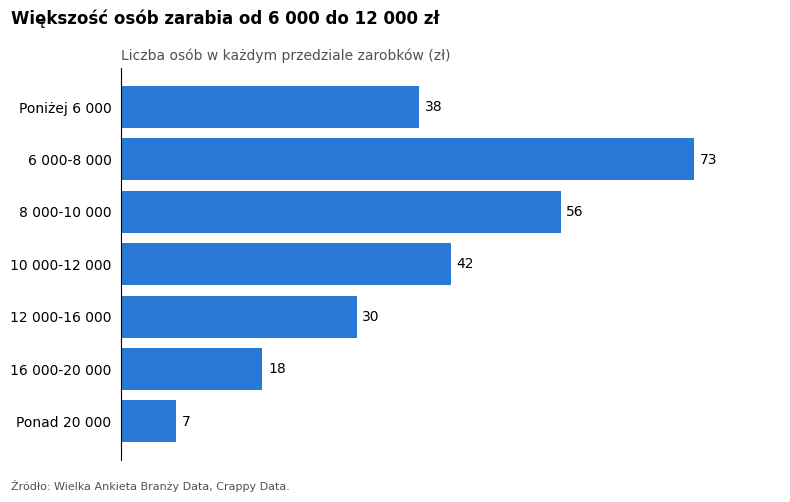

In [19]:
bar_chart(
    band_counts,
    "Większość osób zarabia od 6 000 do 12 000 zł",
    "Liczba osób w każdym przedziale zarobków (zł)",
    number_format="{:.0f}",
)

Teraz obliczamy główne liczby. **Kwartyle** dzielą osoby na 4 równe grupy. Na przykład 25% osób zarabia mniej niż pierwszy kwartyl. Dodajemy też 10. i 90. percentyl, które pokazują, gdzie jest większość osób.

Nie używamy najniższej ani najwyższej wartości, bo pokazałyby zarobki pojedynczych osób.

In [20]:
pay_summary = pd.Series({
    "10. percentyl": df["pay"].quantile(0.10),
    "1. kwartyl (25%)": df["pay"].quantile(0.25),
    "Mediana (50%)": df["pay"].median(),
    "Średnia": df["pay"].mean(),
    "3. kwartyl (75%)": df["pay"].quantile(0.75),
    "90. percentyl": df["pay"].quantile(0.90),
}).round(0)

Pokazujemy te liczby na wykresie. Jest podobny do wykresu pudełkowego, ale nie pokazuje pojedynczych osób:

- **Ciemny pas:** środkowe 50% osób, od 1. do 3. kwartyla.
- **Jasny pas:** środkowe 80% osób, od 10. do 90. percentyla.
- **Linia:** mediana. **Punkt:** średnia.

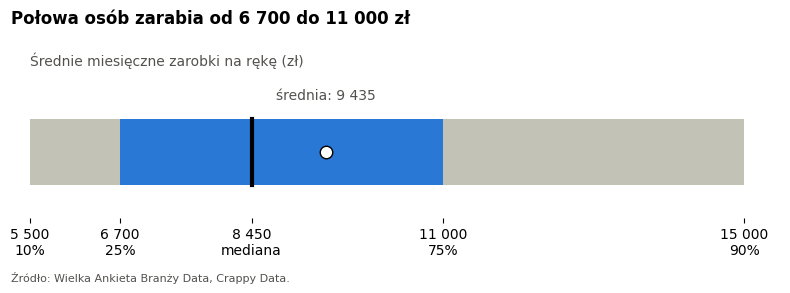

In [21]:
p10 = pay_summary["10. percentyl"]
q1 = pay_summary["1. kwartyl (25%)"]
median = pay_summary["Mediana (50%)"]
mean = pay_summary["Średnia"]
q3 = pay_summary["3. kwartyl (75%)"]
p90 = pay_summary["90. percentyl"]

fig, ax = plt.subplots(figsize=(8, 2.8))

# Rysujemy dwa pasy, linię mediany i punkt średniej
ax.barh(0, p90 - p10, left=p10, height=0.5, color=GRAY)
ax.barh(0, q3 - q1, left=q1, height=0.5, color=BLUE)
ax.plot([median, median], [-0.25, 0.25], color="black", linewidth=3)
ax.plot(mean, 0, "o", color="white", markeredgecolor="black", markersize=9)

# Wpisujemy wartości pod wykresem
ax.set_xticks([p10, q1, median, q3, p90])
ax.set_xticklabels([polish_number(label) for label in [
    f"{p10:,.0f}\n10%",
    f"{q1:,.0f}\n25%",
    f"{median:,.0f}\nmediana",
    f"{q3:,.0f}\n75%",
    f"{p90:,.0f}\n90%",
]])
ax.text(mean, 0.4, polish_number(f"średnia: {mean:,.0f}"), ha="center", color=DARK_GRAY)

# Porządkujemy wykres i dodajemy tekst
ax.set_yticks([])
ax.set_ylim(-0.5, 0.6)
ax.spines["left"].set_visible(False)
fig.suptitle("Połowa osób zarabia od 6 700 do 11 000 zł", x=0.02, ha="left", fontweight="bold")
ax.set_title("Średnie miesięczne zarobki na rękę (zł)", loc="left", fontsize=10, color=DARK_GRAY)
fig.text(0.02, 0.01, SOURCE, fontsize=8, color=DARK_GRAY)
fig.tight_layout(rect=(0, 0.04, 1, 1))
plt.show()

Zanim wybierzemy test, sprawdzamy **kształt** danych. Test Shapiro-Wilka sprawdza, czy dane mają rozkład normalny, a skośność pokazuje, czy dane mają długi ogon. Wartość bliska 0 oznacza, że dane są dość symetryczne.

In [22]:
log_pay = np.log(df["pay"])

print("Skośność zarobków:", round(df["pay"].skew(), 2))
print("P-value testu Shapiro-Wilka dla zarobków:", stats.shapiro(df["pay"]).pvalue)
print("Skośność logarytmu zarobków:", round(log_pay.skew(), 2))
print("P-value testu Shapiro-Wilka dla logarytmu zarobków:", stats.shapiro(log_pay).pvalue)

Skośność zarobków: 1.69
P-value testu Shapiro-Wilka dla zarobków: 1.4438189610865625e-14
Skośność logarytmu zarobków: 0.53
P-value testu Shapiro-Wilka dla logarytmu zarobków: 0.00036531104403978956


**Co widzimy:**

- Mediana zarobków to 8 450 zł, a środkowa połowa osób zarabia od 6 700 do 11 000 zł.
- Średnia (9 435 zł) jest wyższa niż mediana, bo kilka wysokich zarobków ją podnosi.
- Zarobki mają długi ogon (skośność 1,69) i nie mają rozkładu normalnego (p < 0,001). Logarytm zarobków jest dużo bardziej symetryczny (0,53), ale nadal nie jest w pełni normalny.

**Decyzje:**

- Do opisu zarobków używamy **mediany**.
- Grupy porównujemy **testem Kruskala-Wallisa**, bo nie wymaga on rozkładu normalnego.
- W regresji i w modelach uczenia maszynowego używamy **logarytmu zarobków**.

## 1.2 Forma zatrudnienia

Najpierw musimy sprawdzić formę zatrudnienia, bo może ona zmienić wszystkie kolejne porównania.

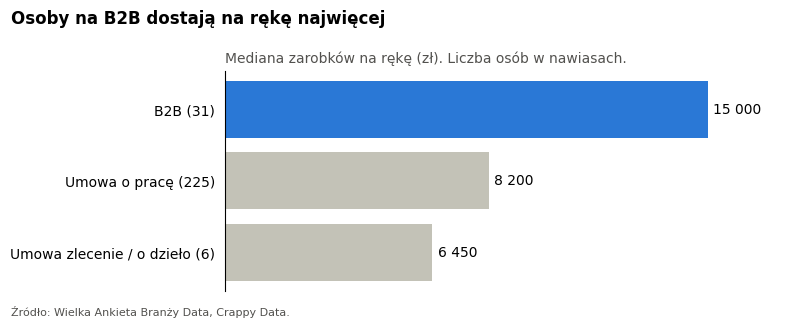

In [23]:
contract_table = pay_table(df, "contract").sort_values("median", ascending=False)

median_chart(contract_table, "Osoby na B2B dostają na rękę najwięcej", highlight=["B2B"])

In [24]:
contract_p, contract_effect = compare_groups(df, "contract", "pay")

print("P-value:", contract_p)
print("Wielkość efektu:", round(contract_effect, 3))

P-value: 1.1644807766612176e-08
Wielkość efektu: 0.133


**Co widzimy:** mediana to 15 000 zł na B2B i 8 200 zł na umowie o pracę. Efekt jest bliski dużego (0,133).

**Co to znaczy:** zarobki to tutaj kwota po podatkach i ZUS, więc jest to duża różnica w pieniądzach, które ludzie dostają.

**Uwaga:** to nie pokazuje, że B2B jest po prostu lepsze. Osoby na B2B zwykle nie mają płatnego urlopu ani zwolnienia lekarskiego, a niektóre z nich mogły liczyć zarobki w inny sposób. Mogą też wykonywać inną pracę, dlatego w części 2 porównujemy podobne osoby.

**Decyzja:** formę zatrudnienia uwzględniamy we wszystkich uczciwych porównaniach, a główny model powtarzamy tylko dla umów o pracę w rozdziale 2.5.

## 1.3 Stanowisko, poziom stanowiska i doświadczenie

Zaczynamy od stanowiska.

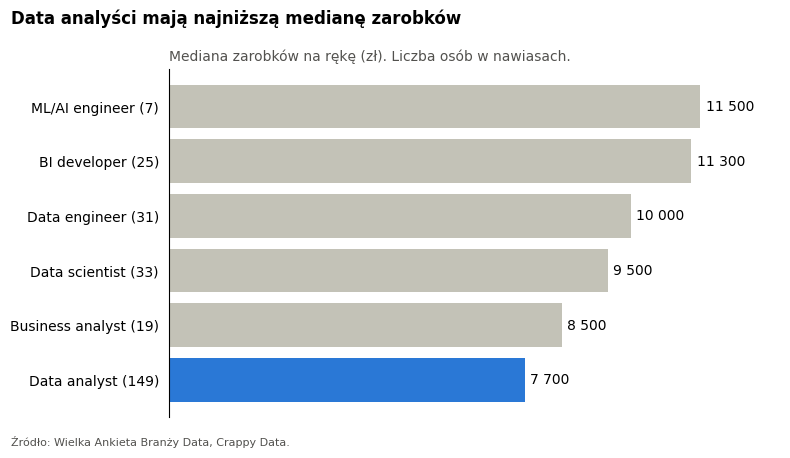

In [25]:
position_table = pay_table(df, "position").sort_values("median", ascending=False)

median_chart(position_table, "Data analyści mają najniższą medianę zarobków", highlight=["Data analyst"])

In [26]:
position_p, position_effect = compare_groups(df, "position", "pay")

print("P-value:", position_p)
print("Wielkość efektu:", round(position_effect, 3))

P-value: 0.0002579845058403151
Wielkość efektu: 0.072


Następnie sprawdzamy poziom stanowiska.

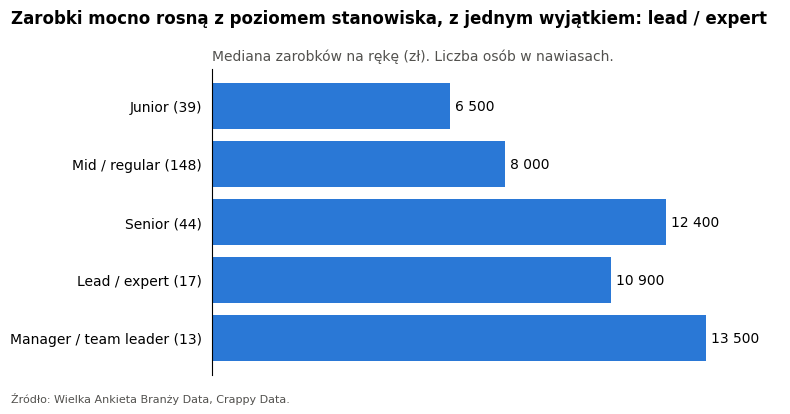

In [27]:
seniority_order = ["Junior", "Mid / regular", "Senior", "Lead / expert", "Manager / team leader"]

seniority_table = pay_table(df, "seniority").loc[seniority_order]

median_chart(seniority_table, "Zarobki mocno rosną z poziomem stanowiska, z jednym wyjątkiem: lead / expert")

In [28]:
seniority_p, seniority_effect = compare_groups(df, "seniority", "pay")

print("P-value:", seniority_p)
print("Wielkość efektu:", round(seniority_effect, 3))

P-value: 2.5615893263673938e-18
Wielkość efektu: 0.331


Na koniec sprawdzamy całkowite doświadczenie.

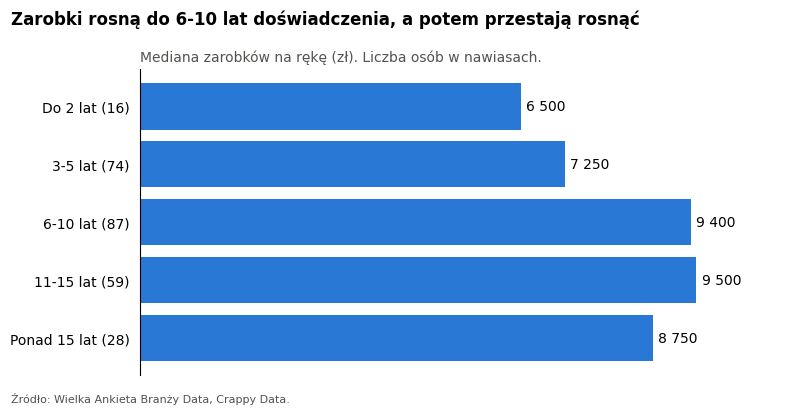

In [29]:
experience_order = ["Do 2 lat", "3-5 lat", "6-10 lat", "11-15 lat", "Ponad 15 lat"]

experience_table = pay_table(df, "experience").loc[experience_order]

median_chart(experience_table, "Zarobki rosną do 6-10 lat doświadczenia, a potem przestają rosnąć")

In [30]:
experience_p, experience_effect = compare_groups(df, "experience", "pay")

print("P-value:", experience_p)
print("Wielkość efektu:", round(experience_effect, 3))

P-value: 1.3812634709695073e-05
Wielkość efektu: 0.092


**Co widzimy:**

- **Poziom stanowiska ma największy efekt ze wszystkich czynników (0,331).** Mediana rośnie od 6 500 zł (junior) do 13 500 zł (manager). Jeden wyjątek: lead / expert (10 900 zł) jest poniżej seniora (12 400 zł), ale ta grupa ma tylko 17 osób.
- **Doświadczenie ma średni efekt (0,092).** Zarobki rosną do 6-10 lat, a potem przestają rosnąć.
- **Stanowisko ma średni efekt (0,072).** Mediana to 7 700 zł dla data analystów i 10 000 zł dla data engineerów. Grupa ML/AI ma wysokie zarobki, ale liczy tylko 7 osób.

**Decyzja:** te czynniki są ze sobą powiązane, więc w części 2 porównamy osoby o podobnym stanowisku, poziomie, doświadczeniu i innych kolumnach tła.

## 1.4 Wykształcenie i płeć

Zaczynamy od kierunku wykształcenia. Dane zawierają tylko pierwszy kierunek z listy każdej osoby.

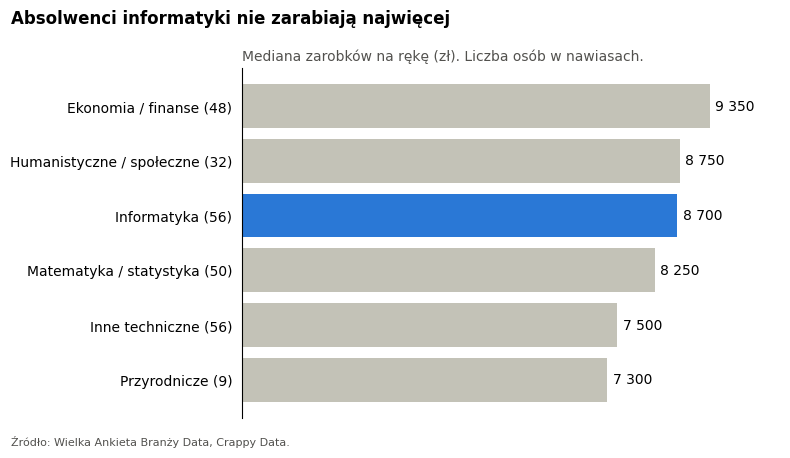

In [31]:
field_table = pay_table(df, "education_field").sort_values("median", ascending=False)

# Szare słupki: tutaj nie spodziewamy się wyraźnej różnicy
median_chart(field_table, "Absolwenci informatyki nie zarabiają najwięcej", highlight=["Informatyka"])

In [32]:
field_p, field_effect = compare_groups(df, "education_field", "pay")

print("P-value:", round(field_p, 3))
print("Wielkość efektu:", round(field_effect, 3))

P-value: 0.21
Wielkość efektu: 0.009


Teraz sprawdzamy płeć.

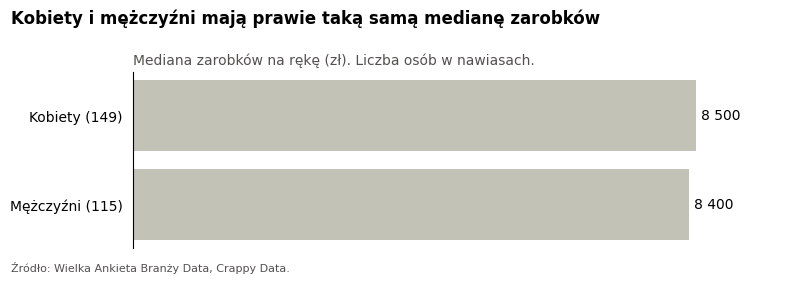

In [33]:
gender_table = pay_table(df, "gender")

median_chart(gender_table, "Kobiety i mężczyźni mają prawie taką samą medianę zarobków", highlight=[])

Sprawdzamy też średnią, bo może ona pokazać inny obraz.

In [34]:
df.groupby("gender")["pay"].mean().round(0)

gender
Kobiety      9179.0
Mężczyźni    9767.0
Name: pay, dtype: float64

In [35]:
gender_p, gender_effect = compare_groups(df, "gender", "pay")

print("P-value:", round(gender_p, 3))
print("Wielkość efektu:", round(gender_effect, 3))

P-value: 0.193
Wielkość efektu: 0.003


**Co widzimy:**

- **Kierunek wykształcenia:** nie widzimy wyraźnej różnicy (p = 0,210). Osoby po informatyce nie mają najwyższej mediany.
- **Płeć:** mediany są prawie takie same (8 500 zł dla kobiet i 8 400 zł dla mężczyzn), a różnica nie jest wyraźna (p = 0,193).

Oba czynniki sprawdzamy jeszcze raz w części 2.

## 1.5 Rodzaj firmy

Zaczynamy od kapitału firmy.

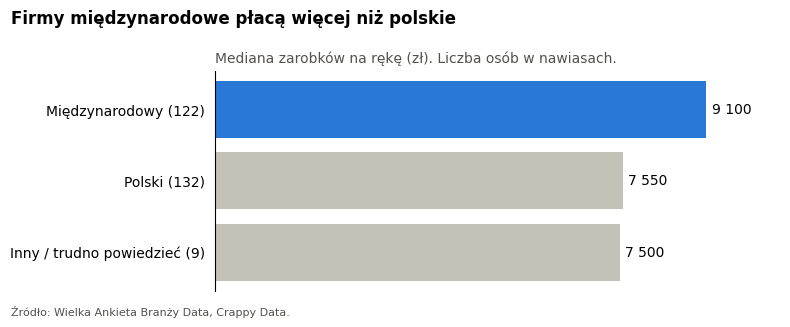

In [36]:
capital_table = pay_table(df, "company_capital").sort_values("median", ascending=False)

median_chart(capital_table, "Firmy międzynarodowe płacą więcej niż polskie", highlight=["Międzynarodowy"])

In [37]:
capital_p, capital_effect = compare_groups(df, "company_capital", "pay")

print("P-value:", capital_p)
print("Wielkość efektu:", round(capital_effect, 3))

P-value: 0.0001075147850485364
Wielkość efektu: 0.063


Teraz sprawdzamy wielkość firmy.

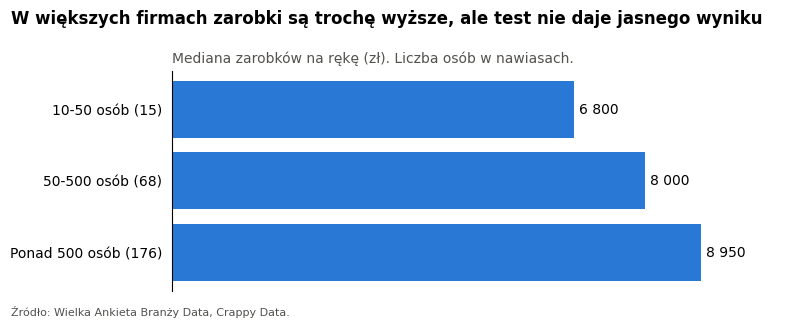

In [38]:
size_order = ["10-50 osób", "50-500 osób", "Ponad 500 osób"]

size_table = pay_table(df, "company_size").loc[size_order]

median_chart(size_table, "W większych firmach zarobki są trochę wyższe, ale test nie daje jasnego wyniku")

In [39]:
size_p, size_effect = compare_groups(df, "company_size", "pay")

print("P-value:", round(size_p, 3))
print("Wielkość efektu:", round(size_effect, 3))

P-value: 0.057
Wielkość efektu: 0.015


**Co widzimy:**

- **Kapitał:** mediana to 9 100 zł w firmach międzynarodowych i 7 550 zł w firmach polskich. Efekt jest średni (0,063, p < 0,001).
- **Wielkość:** mediana rośnie z wielkością firmy, od 6 800 zł do 8 950 zł, ale test nie daje jasnego wyniku (p = 0,057).

**To ciekawe**, bo pracodawcę można wybrać. Następnie sprawdzamy, czy znaczenie ma też miejsce zamieszkania.

## 1.6 Gdzie ludzie mieszkają

Ankieta nie pyta o dokładne miasto, ale pyta o wielkość miejscowości, w której mieszka dana osoba.

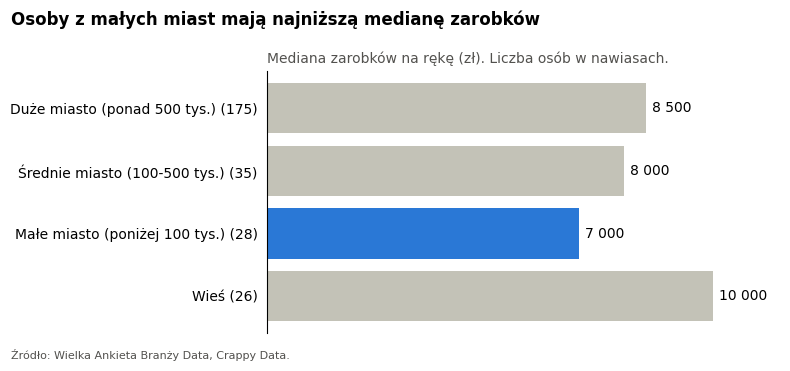

In [40]:
city_order = ["Duże miasto (ponad 500 tys.)", "Średnie miasto (100-500 tys.)", "Małe miasto (poniżej 100 tys.)", "Wieś"]

city_table = pay_table(df, "city_size").loc[city_order]

median_chart(city_table, "Osoby z małych miast mają najniższą medianę zarobków", highlight=["Małe miasto (poniżej 100 tys.)"])

In [41]:
city_p, city_effect = compare_groups(df, "city_size", "pay")

print("P-value:", round(city_p, 3))
print("Wielkość efektu:", round(city_effect, 3))

P-value: 0.031
Wielkość efektu: 0.023


**Co widzimy:**

- **Osoby z małych miast mają najniższą medianę zarobków** (7 000 zł). W dużych miastach to 8 500 zł.
- **Osoby ze wsi mają najwyższą medianę** (10 000 zł), ale ta grupa liczy tylko 26 osób. Nie wiemy, dlaczego tak jest. Jednym z możliwych powodów jest praca zdalna dla firm z dużych miast, ale tego nie sprawdzaliśmy.
- **Test daje jasny wynik (p = 0,031), ale efekt jest mały (0,023).**

**Decyzja:** wielkość miejscowości może zmieniać inne porównania, więc dodajemy ją do kolumn tła w części 2 i do modeli w części 3.

Następnie przyglądamy się czemuś, co łatwiej zmienić: umiejętnościom.

## 1.7 Python

Python jest częstszy na niektórych stanowiskach, a te stanowiska mogą być lepiej płatne. Dlatego najpierw porównujemy wszystkich, a potem tylko data analystów, bo to największa grupa. W kolumnie `python` wartość `1` oznacza, że dana osoba używa Pythona.

In [42]:
data_analysts = df[df["position"] == "Data analyst"]

everyone_python = pay_table(df, "python")
analyst_python = pay_table(data_analysts, "python")

Łączymy cztery grupy w jedną tabelę, żeby narysować je razem.

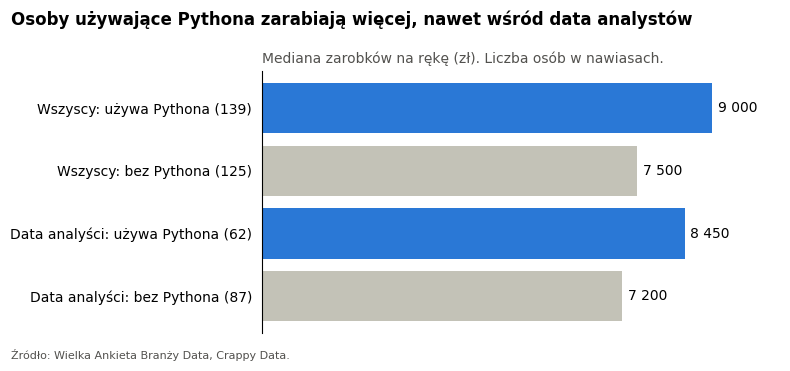

In [43]:
python_table = pd.DataFrame({
    "people": [
        everyone_python.loc[1, "people"],
        everyone_python.loc[0, "people"],
        analyst_python.loc[1, "people"],
        analyst_python.loc[0, "people"],
    ],
    "median": [
        everyone_python.loc[1, "median"],
        everyone_python.loc[0, "median"],
        analyst_python.loc[1, "median"],
        analyst_python.loc[0, "median"],
    ],
}, index=[
    "Wszyscy: używa Pythona",
    "Wszyscy: bez Pythona",
    "Data analyści: używa Pythona",
    "Data analyści: bez Pythona",
])

median_chart(
    python_table,
    "Osoby używające Pythona zarabiają więcej, nawet wśród data analystów",
    highlight=["Wszyscy: używa Pythona", "Data analyści: używa Pythona"],
)

In [44]:
python_p, python_effect = compare_groups(data_analysts, "python", "pay")

print("P-value:", round(python_p, 4))
print("Wielkość efektu:", round(python_effect, 3))

P-value: 0.0028
Wielkość efektu: 0.054


**Co widzimy:** wśród data analystów mediana to 8 450 zł z Pythonem i 7 200 zł bez niego (p = 0,003). Python wiąże się więc z wyższymi zarobkami nawet w obrębie jednego stanowiska. Efekt jest bliski średniego (0,054).

## 1.8 Podsumowanie testów

Przeprowadziliśmy wiele testów. Gdy testów jest dużo, niektóre wyniki mogą wyglądać na mocne tylko przez przypadek. **Korekta Holma** sprawia, że p-value są bezpieczniejsze.

In [45]:
test_results = pd.DataFrame(
    [
        ["Poziom stanowiska", seniority_p, seniority_effect],
        ["Forma zatrudnienia", contract_p, contract_effect],
        ["Stanowisko", position_p, position_effect],
        ["Doświadczenie", experience_p, experience_effect],
        ["Kapitał firmy", capital_p, capital_effect],
        ["Python (data analyści)", python_p, python_effect],
        ["Wielkość firmy", size_p, size_effect],
        ["Wielkość miejscowości", city_p, city_effect],
        ["Kierunek wykształcenia", field_p, field_effect],
        ["Płeć", gender_p, gender_effect],
    ],
    columns=["factor", "p_value", "effect_size"],
)

test_results["corrected_p"] = multipletests(test_results["p_value"], method="holm")[1]
test_results.sort_values("effect_size", ascending=False).round(4)

,factor,p_value,effect_size,corrected_p
0,Poziom stanowiska,0.0000,0.3306,0.0000
1,Forma zatrudnienia,0.0000,0.1333,0.0000
3,Doświadczenie,0.0000,0.0918,0.0001
2,Stanowisko,0.0003,0.0721,0.0015
4,Kapitał firmy,0.0001,0.0626,0.0008
5,Python (data analyści),0.0028,0.0539,0.0141
7,Wielkość miejscowości,0.0305,0.0227,0.1221
6,Wielkość firmy,0.0566,0.0146,0.1699
8,Kierunek wykształcenia,0.2105,0.0087,0.3864
9,Płeć,0.1932,0.0026,0.3864


Wykres pokazuje wielkość każdej różnicy. Niebieskie czynniki dają jasny wynik po korekcie.

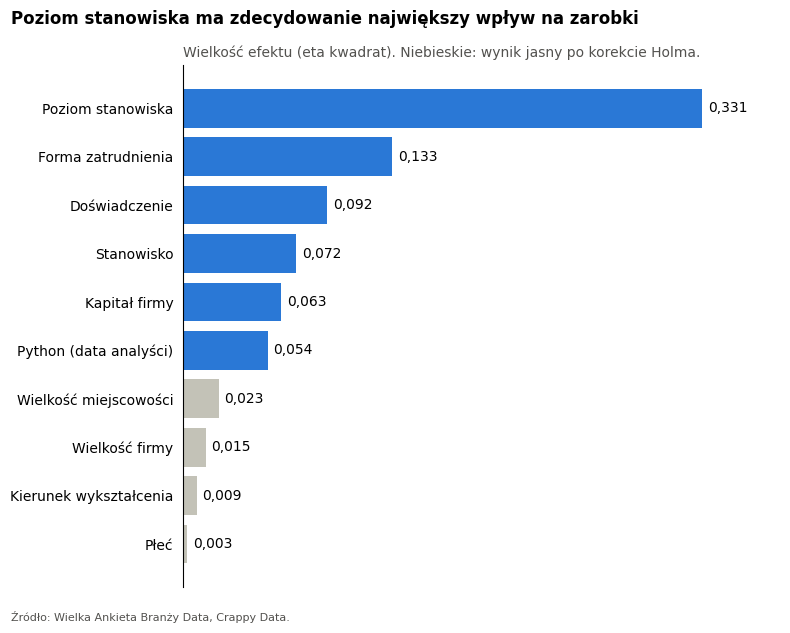

In [46]:
clear_factors = test_results[test_results["corrected_p"] < 0.05]["factor"].tolist()
effect_sizes = test_results.set_index("factor")["effect_size"].sort_values(ascending=False)

bar_chart(
    effect_sizes,
    "Poziom stanowiska ma zdecydowanie największy wpływ na zarobki",
    "Wielkość efektu (eta kwadrat). Niebieskie: wynik jasny po korekcie Holma.",
    highlight=clear_factors,
    number_format="{:.3f}",
)

**Co widzimy:** po korekcie 6 z 10 czynników daje jasny wynik: poziom stanowiska, forma zatrudnienia, doświadczenie, stanowisko, kapitał firmy i Python. Wielkość miejscowości (0,122 po korekcie), wielkość firmy, kierunek wykształcenia i płeć nie dają jasnego wyniku.

**Następny krok:** te testy sprawdzają jeden czynnik naraz, więc nie mówią, czy dany czynnik ma znaczenie sam w sobie. Na przykład firmy międzynarodowe mogą po prostu zatrudniać więcej seniorów. Regresja pozwala to sprawdzić.

---
# Część 2: Co zostaje, gdy porównujemy podobne osoby?

Powyższe testy sprawdzają jeden czynnik naraz. Ale czynniki się nakładają. Na przykład osoby używające Pythona mogą też mieć wyższe stanowiska.

**Regresja liniowa** sprawdza wiele czynników jednocześnie. Każdy wynik pokazuje związek jednego czynnika, gdy pozostałe czynniki są takie same.

## 2.1 Jakie umiejętności uwzględnić?

Ankieta wymienia wiele narzędzi i zadań. Najpierw robimy ich listę. Zostawiamy umiejętności, które ma co najmniej 15 osób i których nie ma co najmniej 15 osób.

In [47]:
skill_columns = ["python", "cloud_warehouse", "excel"]
for column in df.columns:
    if column.startswith(("narzędzia |", "programowanie |", "czynności |")):
        skill_columns.append(column)

popular_skills = []
for column in skill_columns:
    users = df[column].sum()
    non_users = df[column].notna().sum() - users
    if users >= 15 and non_users >= 15:
        popular_skills.append(column)

print("Umiejętności do sprawdzenia:", len(popular_skills))

Umiejętności do sprawdzenia: 41


Regresja potrzebuje logarytmu zarobków. Dzięki niemu wyniki można pokazać w procentach. Zapisujemy też kolumny tła, których używamy do porównywania podobnych osób.

In [48]:
df["log_pay"] = np.log(df["pay"])

background = "C(position) + C(seniority) + C(experience) + C(contract) + C(work_time) + C(city_size)"

Teraz uruchamiamy jedną regresję dla każdej umiejętności.

In [49]:
skill_results = []

for skill in popular_skills:
    skill_data = df.rename(columns={skill: "skill"})
    skill_model = smf.ols("log_pay ~ skill + " + background, data=skill_data).fit()

    skill_results.append({
        "skill": skill,
        "users": int(df[skill].sum()),
        "pay_difference_%": to_percent(skill_model.params["skill"]),
        "p_value": skill_model.pvalues["skill"],
    })

skill_results = pd.DataFrame(skill_results).sort_values("p_value")

Sprawdzamy wiele umiejętności, więc używamy surowej korekty Bonferroniego. Mnoży ona każde p-value przez liczbę testów.

In [50]:
skill_results["corrected_p"] = (skill_results["p_value"] * len(skill_results)).clip(upper=1)

skill_results.head(6).round(3)

,skill,users,pay_difference_%,p_value,corrected_p
0,python,139,10.990,0.005,0.192
1,cloud_warehouse,39,14.002,0.005,0.216
33,czynności | tworzenie dokumentacji,119,9.019,0.013,0.541
6,narzędzia | airflow,21,16.676,0.019,0.793
2,excel,205,-9.558,0.021,0.879
12,narzędzia | databricks,47,10.795,0.021,0.880


**Co widzimy:** Python (+11,0%) i Snowflake / BigQuery / Redshift (+14,0%) mają najmniejsze p-value. Excel ma wynik ujemny (-9,6%).

**Uwaga:** po surowej korekcie żadna umiejętność nie jest poniżej 0,05. Najbliżej są Python (0,192) i hurtownie danych w chmurze (0,216). Te wyniki są więc obiecujące, ale nie są mocnym dowodem.

**Decyzja:** dodajemy te trzy umiejętności do głównego modelu. Wybraliśmy je po obejrzeniu tej tabeli, więc ich p-value w następnym modelu mogą wyglądać trochę lepiej, niż jest w rzeczywistości.

## 2.2 Budujemy główny model

Najpierw tworzymy proste kolumny tak/nie. W tych kolumnach 1 oznacza tak, a 0 oznacza nie.

In [51]:
model_data = df[df["company_capital"].isin(["Polski", "Międzynarodowy"])].copy()

model_data["international_company"] = (model_data["company_capital"] == "Międzynarodowy").astype(int)
model_data["large_company"] = (model_data["company_size"] == "Ponad 500 osób").astype(int)
model_data["men"] = (model_data["gender"] == "Mężczyźni").astype(int)

Zostawiamy tylko osoby, które odpowiedziały na wszystkie pytania używane w modelu.

In [52]:
model_columns = ["position", "seniority", "experience", "contract", "work_time", "company_size", "city_size"]
model_data = model_data.dropna(subset=model_columns)

print("Osoby w modelu:", model_data.shape[0])

Osoby w modelu: 252


Budujemy model. `cov_type="HC3"` daje bezpieczniejsze p-value, gdy błędy nie są takie same dla wszystkich osób.

In [53]:
factors = "international_company + large_company + python + cloud_warehouse + excel + men"

main_model = smf.ols("log_pay ~ " + factors + " + " + background, data=model_data).fit(cov_type="HC3")

Regresja ma swoje założenia, więc sprawdzamy jej błędy (**reszty**). Ich skośność powinna być bliska 0. Skośność bliska 0 to dobry znak, nawet jeśli reszty nie są idealnie normalne.

In [54]:
print("Skośność reszt:", round(main_model.resid.skew(), 2))
print("P-value testu Shapiro-Wilka dla reszt:", round(stats.shapiro(main_model.resid).pvalue, 4))

Skośność reszt: -0.18
P-value testu Shapiro-Wilka dla reszt: 0.143


Ta komórka zamienia wyniki na procenty.

In [55]:
terms = factors.split(" + ")

main_results = pd.DataFrame({
    "pay_difference_%": to_percent(main_model.params[terms]),
    "ci_low_%": to_percent(main_model.conf_int().loc[terms, 0]),
    "ci_high_%": to_percent(main_model.conf_int().loc[terms, 1]),
    "p_value": main_model.pvalues[terms],
}).round(3)

main_results.sort_values("pay_difference_%", ascending=False)

,pay_difference_%,ci_low_%,ci_high_%,p_value
international_company,13.855,6.753,21.431,0.000
cloud_warehouse,12.234,2.462,22.938,0.013
large_company,11.615,3.088,20.847,0.007
python,9.922,2.276,18.139,0.010
men,-1.358,-8.114,5.896,0.706
excel,-5.984,-14.283,3.117,0.191


Wykres pokazuje każdy wynik razem z jego niepewnością. Jeśli linia przecina 0, wynik nie jest jasny.

In [56]:
chart_data = main_results.sort_values("pay_difference_%").rename(index={
    "international_company": "Firma międzynarodowa",
    "cloud_warehouse": "Snowflake / BigQuery / Redshift",
    "python": "Python",
    "large_company": "Firma z ponad 500 osobami",
    "men": "Mężczyźni (w porównaniu z kobietami)",
    "excel": "Excel / Google Sheets",
})

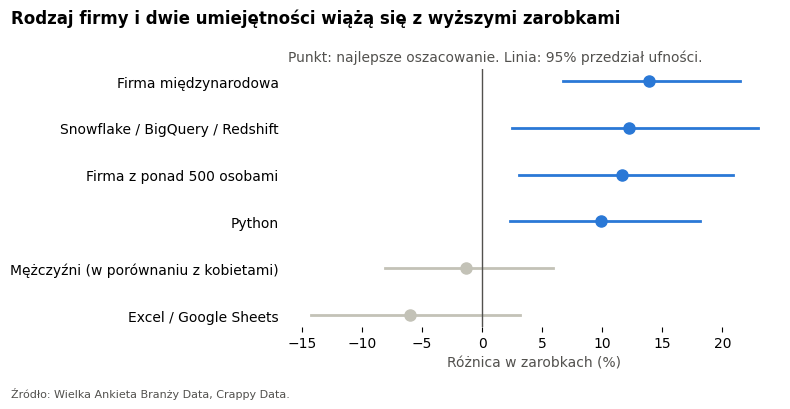

In [57]:
fig, ax = plt.subplots(figsize=(8, 4))

# Rysujemy jedną linię i jeden punkt dla każdego czynnika
for position, (label, row) in enumerate(chart_data.iterrows()):
    is_clear = row["ci_low_%"] > 0 or row["ci_high_%"] < 0
    color = BLUE if is_clear else GRAY
    ax.plot([row["ci_low_%"], row["ci_high_%"]], [position, position], color=color, linewidth=2)
    ax.plot(row["pay_difference_%"], position, "o", color=color, markersize=8)

# Dodajemy linię zera i etykiety
ax.axvline(0, color=DARK_GRAY, linewidth=1)
ax.set_yticks(range(len(chart_data)))
ax.set_yticklabels(chart_data.index)
ax.set_xlabel("Różnica w zarobkach (%)", color=DARK_GRAY)
ax.spines["left"].set_visible(False)

fig.suptitle("Rodzaj firmy i dwie umiejętności wiążą się z wyższymi zarobkami", x=0.02, ha="left", fontweight="bold")
ax.set_title("Punkt: najlepsze oszacowanie. Linia: 95% przedział ufności.", loc="left", fontsize=10, color=DARK_GRAY)
fig.text(0.02, 0.01, SOURCE, fontsize=8, color=DARK_GRAY)
fig.tight_layout(rect=(0, 0.04, 1, 1))
plt.show()

**R²** pokazuje, jaką część różnic w logarytmie zarobków wyjaśnia model. Porównujemy nasz model z modelem, który ma tylko kolumny tła.

In [58]:
background_model = smf.ols("log_pay ~ " + background, data=model_data).fit()

print("R² tylko z kolumnami tła:", round(background_model.rsquared, 3))
print("R² z naszymi czynnikami:", round(main_model.rsquared, 3))

R² tylko z kolumnami tła: 0.555
R² z naszymi czynnikami: 0.645


**Jak to czytać:** procent to różnica w zarobkach w porównaniu z podobnymi osobami.

**Założenia:** reszty wyglądają dobrze. Ich skośność jest bliska 0 (-0,18), a test Shapiro-Wilka nie wykazuje problemu (p = 0,143).

**Co widzimy:**

- **Firma międzynarodowa: +13,9%** (od +6,8% do +21,4%). To najwyraźniejszy wynik (p < 0,001).
- **Snowflake / BigQuery / Redshift: +12,2%** (od +2,5% do +22,9%).
- **Firma z ponad 500 osobami: +11,6%** (od +3,1% do +20,8%).
- **Python: +9,9%** (od +2,3% do +18,1%).
- **Excel i płeć:** brak wyraźnej różnicy.

R² rośnie z 0,555 do 0,645, więc te czynniki dodają około 9 punktów procentowych do tego, co wyjaśniają kolumny tła.

**Szersze spojrzenie:** przedziały są szerokie. Na przykład wynik dla Pythona może być bliski +2% albo bliski +18%. Dlatego patrzymy przede wszystkim na kierunek wyników, a nie tylko na dokładną liczbę.

## 2.3 Czy kierunek wykształcenia coś dodaje?

Dodajemy kierunek wykształcenia do modelu. Następnie test F sprawdza, czy model staje się wyraźnie lepszy.

In [59]:
field_data = model_data.dropna(subset=["education_field"])
field_data = field_data[field_data["education_field"] != "Inne"]

model_without_field = smf.ols("log_pay ~ " + factors + " + " + background, data=field_data).fit()
model_with_field = smf.ols("log_pay ~ C(education_field) + " + factors + " + " + background, data=field_data).fit()

f_value, f_p, degrees = model_with_field.compare_f_test(model_without_field)

print("Liczba osób:", field_data.shape[0])
print("P-value testu F:", round(f_p, 3))

Liczba osób: 240
P-value testu F: 0.913


**Co widzimy:** dodanie kierunku wykształcenia nie poprawia modelu (p = 0,913). Wśród podobnych osób nie widzimy różnicy w zarobkach między kierunkami.

**Uwaga:** dane zawierają tylko pierwszy kierunek z listy każdej osoby, więc ten wynik nie jest idealny.

## 2.4 Czy wynik dla płci zależy od porównania?

Główny model porównuje osoby o tym samym stanowisku i poziomie. Ale jeśli jednej płci trudniej awansować, takie porównanie może ukryć różnicę. Dlatego usuwamy stanowisko i poziom i jeszcze raz sprawdzamy płeć.

In [60]:
gender_formula = "log_pay ~ men + C(experience) + C(contract) + C(work_time) + C(city_size)"

gender_model = smf.ols(gender_formula, data=model_data).fit(cov_type="HC3")

print("Różnica w zarobkach dla mężczyzn (%):", round(to_percent(gender_model.params["men"]), 1))
print("Od (%):", round(to_percent(gender_model.conf_int().loc["men", 0]), 1))
print("Do (%):", round(to_percent(gender_model.conf_int().loc["men", 1]), 1))
print("P-value:", round(gender_model.pvalues["men"], 3))

Różnica w zarobkach dla mężczyzn (%): 1.7
Od (%): -6.8
Do (%): 11.1
P-value: 0.699


**Co widzimy:** bez stanowiska i poziomu wynik dla mężczyzn to +1,7% (od -6,8% do +11,1%, p = 0,699). W żadnym porównaniu nie widzimy więc wyraźnej luki płacowej.

**Uwaga:** to nie dowodzi, że luki nie ma. Przedział jest szeroki, więc luka rzędu kilku procent jest nadal możliwa. Osoby same zdecydowały się wziąć udział w ankiecie, więc próba może nie opisywać całej branży.

## 2.5 Czy wyniki zostają tylko dla umów o pracę?

Praca na B2B ma inne warunki, a niektóre osoby na B2B mogły liczyć zarobki na rękę w inny sposób. Żeby sprawdzić, czy to zmienia nasze wyniki, powtarzamy model tylko dla osób na pełnym etacie z umową o pracę.

In [61]:
is_employment = model_data["contract"] == "Umowa o pracę"
is_full_time = model_data["work_time"] == "Pełny etat"

employment_data = model_data[is_employment & is_full_time]

print("Osoby w tym sprawdzeniu:", employment_data.shape[0])

Osoby w tym sprawdzeniu: 208


In [62]:
employment_formula = "log_pay ~ " + factors + " + C(position) + C(seniority) + C(experience) + C(city_size)"

employment_model = smf.ols(employment_formula, data=employment_data).fit(cov_type="HC3")

Zestawiamy oba wyniki obok siebie.

In [63]:
comparison = pd.DataFrame({
    "all_people_%": main_results["pay_difference_%"],
    "all_people_p": main_results["p_value"],
    "employment_only_%": to_percent(employment_model.params[terms]),
    "employment_only_p": employment_model.pvalues[terms],
}).round(3)

comparison.sort_values("all_people_%", ascending=False)

,all_people_%,all_people_p,employment_only_%,employment_only_p
international_company,13.855,0.000,11.646,0.002
cloud_warehouse,12.234,0.013,9.297,0.088
large_company,11.615,0.007,9.997,0.029
python,9.922,0.010,11.623,0.007
men,-1.358,0.706,2.481,0.495
excel,-5.984,0.191,-7.334,0.118


**Co widzimy:**

- **Firma międzynarodowa (+11,6%, p = 0,002) i Python (+11,6%, p = 0,007) nadal dają jasny wynik.** To nasze najbardziej wiarygodne wyniki.
- **Duże firmy również dają jasny wynik (+10,0%, p = 0,029).**
- **Hurtownie danych w chmurze są słabsze (+9,3%, p = 0,088).** Kierunek się nie zmienia, ale wynik nie jest już jasny.
- **Płeć i Excel nadal nie dają jasnego wyniku.**

**Czego dowiedzieliśmy się w części 2:** miejsce pracy i używanie Pythona wiążą się z zarobkami nawet wśród podobnych osób. Ale te związki nie dowodzą przyczyny. Na przykład osoby używające Pythona mogą też wykonywać bardziej złożoną pracę.

---
# Część 3: Jak dobrze uczenie maszynowe przewiduje zarobki?

Regresja pokazała związki w naszych danych. Teraz zadajemy inne pytanie: **czy model potrafi przewidzieć zarobki osób, których nigdy nie widział?**

## 3.1 Przygotowanie danych dla modeli

Celem jest logarytm zarobków. Nie używamy płci jako cechy, bo chcemy, żeby model porównywał osoby według ich pracy. Sprawdzamy dwa zestawy cech.

In [64]:
job_features = ["position", "seniority", "experience", "contract", "work_time"]
company_features = ["company_capital", "company_size"]
city_features = ["city_size"]

tool_features = ["python", "cloud_warehouse", "excel"]
for column in df.columns:
    if column.startswith(("narzędzia |", "programowanie |")):
        tool_features.append(column)

feature_sets = {
    "Praca + firma + miejscowość": job_features + company_features + city_features,
    "Praca + firma + miejscowość + narzędzia": job_features + company_features + city_features + tool_features,
}

Modele potrzebują liczb, więc przygotowujemy kolumny w **pipeline**:

- **Brakujące odpowiedzi:** uzupełniamy je najczęstszą odpowiedzią.
- **Kolumny tekstowe:** kodowanie one-hot zamienia je na kolumny 0/1. Rzadkie odpowiedzi trafiają do jednej wspólnej grupy.
- **Kolumny liczbowe:** sprowadzamy je do tej samej skali.

Pipeline uczy się tych kroków tylko na danych treningowych. Dzięki temu unikamy **wycieku danych** (data leakage).

In [65]:
def make_model(features, model):
    text_columns = []
    number_columns = []
    for column in features:
        if df[column].dtype == object:
            text_columns.append(column)
        else:
            number_columns.append(column)

    text_steps = make_pipeline(
        SimpleImputer(strategy="most_frequent"),
        OneHotEncoder(handle_unknown="ignore", min_frequency=MIN_PEOPLE, sparse_output=False),
    )
    number_steps = make_pipeline(
        SimpleImputer(strategy="median"),
        StandardScaler(),
    )
    prepare = ColumnTransformer([
        ("text", text_steps, text_columns),
        ("numbers", number_steps, number_columns),
    ])

    return make_pipeline(prepare, model)

## 3.2 Wybór modeli

Porównujemy modele proste i złożone. Wiele modeli ma ustawienia (**hiperparametry**). `GridSearchCV` sprawdza różne ustawienia i zostawia najlepsze. Używa przy tym tylko danych treningowych, więc końcowy test pozostaje uczciwy.

In [66]:
inner_splits = KFold(n_splits=4, shuffle=True, random_state=1)


def tuned(model, settings):
    return GridSearchCV(model, settings, cv=inner_splits, scoring="r2", n_jobs=-1)

Najpierw dodajemy model bazowy i dwa modele liniowe. **Model bazowy** zawsze przewiduje średnią, a przydatny model musi być od niego lepszy. **Ridge** i **Lasso** to modele liniowe, które chronią przed zbyt dużą liczbą cech. Lasso może też usuwać cechy.

In [67]:
models = {
    "Model bazowy": DummyRegressor(),
    "Ridge": RidgeCV(alphas=np.logspace(-2, 3, 12)),
    "Lasso": LassoCV(cv=4, random_state=0, max_iter=20000),
}

Następnie dodajemy **drzewo decyzyjne**. To model najłatwiejszy do wyjaśnienia, bo jest listą prostych reguł tak/nie.

In [68]:
models["Drzewo decyzyjne (dostrojone)"] = tuned(
    DecisionTreeRegressor(random_state=0),
    {"max_depth": [2, 3, 4, 6], "min_samples_leaf": [5, 10, 20]},
)

**Random Forest** buduje wiele drzew jednocześnie i bierze ich średnią.

In [69]:
models["Random Forest (dostrojony)"] = tuned(
    RandomForestRegressor(n_estimators=200, random_state=0),
    {"min_samples_leaf": [1, 3, 5, 10], "max_features": [0.3, 0.6, 1.0]},
)

**Boosting** buduje małe drzewa jedno po drugim, a każde nowe drzewo próbuje poprawić błędy poprzednich. Najpierw sprawdzamy XGBoost z domyślnymi ustawieniami.

In [70]:
models["XGBoost (domyślny)"] = XGBRegressor(random_state=0, n_jobs=1, verbosity=0)

Teraz dodajemy wersje dostrojone.

In [71]:
xgboost_settings = {
    "n_estimators": [100, 300],
    "learning_rate": [0.02, 0.05],
    "max_depth": [1, 2, 3],
    "min_child_weight": [1, 5],
    "reg_lambda": [1, 10],
}

models["XGBoost (dostrojony)"] = tuned(
    XGBRegressor(random_state=0, n_jobs=1, verbosity=0, subsample=0.8, colsample_bytree=0.8),
    xgboost_settings,
)

In [72]:
lightgbm_settings = {
    "n_estimators": [100, 300],
    "learning_rate": [0.02, 0.05],
    "num_leaves": [2, 4, 8],
    "min_child_samples": [5, 20],
    "reg_lambda": [0, 10],
}

models["LightGBM (dostrojony)"] = tuned(
    LGBMRegressor(random_state=0, n_jobs=1, verbose=-1, subsample=0.8, subsample_freq=1, colsample_bytree=0.8),
    lightgbm_settings,
)

## 3.3 Porównanie modeli

Używamy **walidacji krzyżowej**. Dane dzielimy na 5 części, a każda część jest raz używana jako nowe, niewidziane dane. Powtarzamy to 5 razy z różnymi podziałami, żeby wynik nie zależał od jednego szczęśliwego podziału.

**Uwaga:** następna komórka może działać kilka minut, bo trenuje wiele modeli.

In [73]:
target = df["log_pay"]
splits = RepeatedKFold(n_splits=5, n_repeats=5, random_state=0)

model_results = []

for set_name, features in feature_sets.items():
    for model_name, model in models.items():
        scores = cross_validate(
            make_model(features, model),
            df[features],
            target,
            cv=splits,
            scoring=["r2", "neg_mean_absolute_error"],
            return_train_score=True,
        )
        model_results.append({
            "features": set_name,
            "model": model_name,
            "r2_new_people": scores["test_r2"].mean(),
            "r2_std": scores["test_r2"].std(),
            "r2_training": scores["train_r2"].mean(),
            "typical_error_%": to_percent(-scores["test_neg_mean_absolute_error"].mean()),
        })

model_results = pd.DataFrame(model_results)

Najpierw patrzymy na wszystkie wyniki dla każdego zestawu cech.

In [74]:
model_results[model_results["features"] == "Praca + firma + miejscowość"].sort_values("r2_new_people", ascending=False).round(3)

,features,model,r2_new_people,r2_std,r2_training,typical_error_%
2,Praca + firma + miejscowość,Lasso,0.503,0.115,0.620,22.817
1,Praca + firma + miejscowość,Ridge,0.494,0.112,0.619,23.016
7,Praca + firma + miejscowość,LightGBM (dostrojony),0.489,0.117,0.632,23.185
6,Praca + firma + miejscowość,XGBoost (dostrojony),0.473,0.131,0.643,23.493
4,Praca + firma + miejscowość,Random Forest (dostrojony),0.424,0.128,0.695,24.601
5,Praca + firma + miejscowość,XGBoost (domyślny),0.282,0.161,0.903,27.460
3,Praca + firma + miejscowość,Drzewo decyzyjne (dostrojone),0.261,0.187,0.494,28.142
0,Praca + firma + miejscowość,Model bazowy,-0.022,0.032,0.000,35.562


In [75]:
model_results[model_results["features"] == "Praca + firma + miejscowość + narzędzia"].sort_values("r2_new_people", ascending=False).round(3)

,features,model,r2_new_people,r2_std,r2_training,typical_error_%
15,Praca + firma + miejscowość + narzędzia,LightGBM (dostrojony),0.515,0.097,0.673,22.524
14,Praca + firma + miejscowość + narzędzia,XGBoost (dostrojony),0.513,0.110,0.676,22.533
10,Praca + firma + miejscowość + narzędzia,Lasso,0.502,0.093,0.663,23.341
9,Praca + firma + miejscowość + narzędzia,Ridge,0.475,0.109,0.696,24.069
12,Praca + firma + miejscowość + narzędzia,Random Forest (dostrojony),0.435,0.113,0.794,24.566
11,Praca + firma + miejscowość + narzędzia,Drzewo decyzyjne (dostrojone),0.272,0.171,0.520,27.767
13,Praca + firma + miejscowość + narzędzia,XGBoost (domyślny),0.265,0.172,0.994,27.607
8,Praca + firma + miejscowość + narzędzia,Model bazowy,-0.022,0.032,0.000,35.562


Teraz pokazujemy 8 najlepszych kombinacji na wykresie.

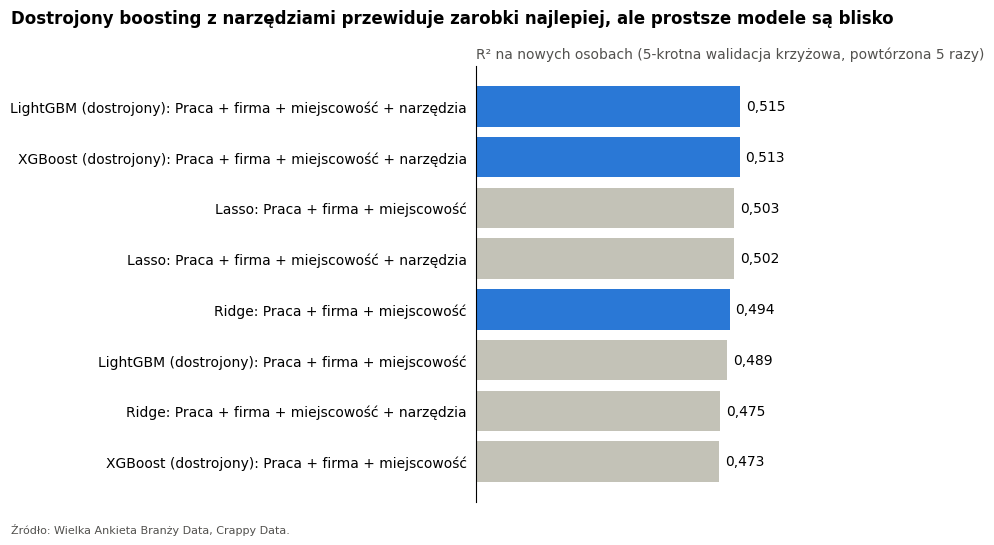

In [76]:
chart_models = model_results.copy()
chart_models["name"] = chart_models["model"] + ": " + chart_models["features"]
chart_models = chart_models.set_index("name")["r2_new_people"].sort_values(ascending=False).head(8)

bar_chart(
    chart_models,
    "Dostrojony boosting z narzędziami przewiduje zarobki najlepiej, ale prostsze modele są blisko",
    "R² na nowych osobach (5-krotna walidacja krzyżowa, powtórzona 5 razy)",
    highlight=["XGBoost (dostrojony): Praca + firma + miejscowość + narzędzia", "LightGBM (dostrojony): Praca + firma + miejscowość + narzędzia", "Ridge: Praca + firma + miejscowość"],
    number_format="{:.3f}",
)

**Co widzimy:**

- **Wszystkie prawdziwe modele są wyraźnie lepsze od modelu bazowego.** Model bazowy ma typowy błąd około 36%. Najlepsze modele mają około 23%.
- **Najdokładniejsze są dostrojony LightGBM (R² = 0,515) i XGBoost (0,513) z narzędziami.** Są praktycznie równe.
- **Prostsze modele są blisko.** Lasso ma 0,502 z narzędziami i 0,503 bez nich. Ridge ma 0,494 z kolumnami pracy, firmy i miejscowości.
- **Proste drzewo decyzyjne jest dużo słabsze** (0,261), a dostrojony Random Forest nie wygrywa z najlepszymi prostymi modelami liniowymi (0,435 z narzędziami).

**Uwaga:** R² zmienia się o około 0,1 między różnymi podziałami, więc małe różnice między najlepszymi modelami nie są ważne. Narzędzia dodają do przewidywań niewiele.

### Czym jest przeuczenie?

Model jest **przeuczony** (overfitting), gdy uczy się danych treningowych zbyt dobrze, ale nie potrafi przewidywać dla nowych osób. Porównujemy XGBoost z ustawieniami domyślnymi i dostrojonymi.

In [77]:
is_xgboost = model_results["model"].str.startswith("XGBoost")
is_tools = model_results["features"] == "Praca + firma + miejscowość + narzędzia"

overfit = model_results[is_xgboost & is_tools].set_index("model")

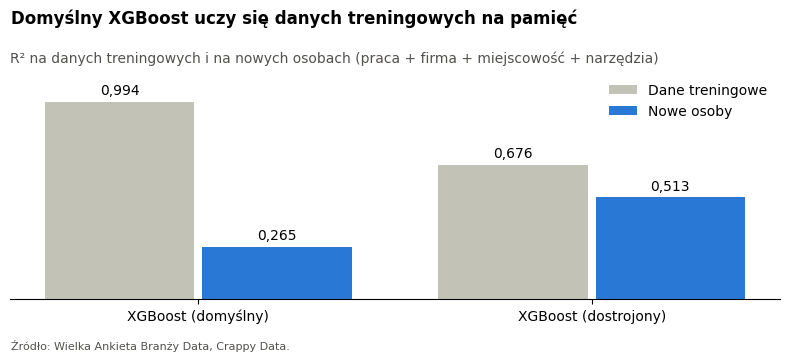

In [78]:
fig, ax = plt.subplots(figsize=(8, 3.5))
positions = np.arange(len(overfit))

# Szare słupki: dane treningowe. Niebieskie słupki: nowe osoby.
training_bars = ax.bar(positions - 0.2, overfit["r2_training"], width=0.38, color=GRAY, label="Dane treningowe")
new_bars = ax.bar(positions + 0.2, overfit["r2_new_people"], width=0.38, color=BLUE, label="Nowe osoby")
ax.bar_label(training_bars, [polish_number(f"{value:.3f}") for value in overfit["r2_training"]], padding=3)
ax.bar_label(new_bars, [polish_number(f"{value:.3f}") for value in overfit["r2_new_people"]], padding=3)

ax.set_xticks(positions)
ax.set_xticklabels(overfit.index)
ax.set_yticks([])
ax.set_ylim(0, 1.15)
ax.spines["left"].set_visible(False)
ax.spines["bottom"].set_visible(True)
ax.legend(frameon=False, loc="upper right")

fig.suptitle("Domyślny XGBoost uczy się danych treningowych na pamięć", x=0.02, ha="left", fontweight="bold")
ax.set_title("R² na danych treningowych i na nowych osobach (praca + firma + miejscowość + narzędzia)", loc="left", fontsize=10, color=DARK_GRAY)
fig.text(0.02, 0.01, SOURCE, fontsize=8, color=DARK_GRAY)
fig.tight_layout(rect=(0, 0.04, 1, 1))
plt.show()

**Co widzimy:** XGBoost z ustawieniami domyślnymi ma prawie idealne wyniki na danych treningowych (0,994), ale jest słaby na nowych osobach (0,265). To wyraźne przeuczenie. Z dostrojonymi ustawieniami obie liczby są dużo bliżej siebie (0,676 i 0,513).

**Czego się dowiedzieliśmy:** przy małym zbiorze danych ustawienia mogą znaczyć więcej niż nazwa algorytmu.

## 3.4 Czy potrzebujemy więcej osób, czy więcej informacji?

**Krzywa uczenia** trenuje model na coraz większej liczbie osób. Jeśli wynik na nowych osobach nadal rośnie, więcej osób prawdopodobnie by pomogło. Jeśli przestaje rosnąć, potrzebujemy raczej nowych informacji, a nie więcej osób.

Najpierw szukamy najlepszych ustawień LightGBM dla danych z narzędziami.

In [79]:
tools_features = feature_sets["Praca + firma + miejscowość + narzędzia"]

lightgbm_search = make_model(tools_features, models["LightGBM (dostrojony)"]).fit(df[tools_features], target)
best_lightgbm_settings = lightgbm_search[-1].best_params_

print(best_lightgbm_settings)

{'learning_rate': 0.05, 'min_child_samples': 5, 'n_estimators': 300, 'num_leaves': 2, 'reg_lambda': 0}


Używamy tych ustawień, żeby zbudować końcowy model LightGBM. Ustawienia wybraliśmy na wszystkich danych, więc tego modelu używamy tylko do krzywej uczenia i sprawdzeń poniżej, a nie do mierzenia jego dokładności.

In [80]:
final_lightgbm = LGBMRegressor(
    random_state=0, n_jobs=1, verbose=-1, subsample=0.8, subsample_freq=1, colsample_bytree=0.8,
    **best_lightgbm_settings,
)

Teraz obliczamy krzywe uczenia.

In [81]:
curve_models = {
    "Ridge (praca + firma + miejscowość)": (feature_sets["Praca + firma + miejscowość"], RidgeCV(alphas=np.logspace(-2, 3, 12))),
    "Random Forest (praca + firma + miejscowość)": (feature_sets["Praca + firma + miejscowość"], RandomForestRegressor(n_estimators=200, min_samples_leaf=3, random_state=0)),
    "LightGBM (praca + firma + miejscowość + narzędzia)": (tools_features, final_lightgbm),
}

curve_splits = RepeatedKFold(n_splits=5, n_repeats=3, random_state=0)
curve_rows = []

for name, (features, model) in curve_models.items():
    sizes, train_scores, test_scores = learning_curve(
        make_model(features, model),
        df[features],
        target,
        cv=curve_splits,
        train_sizes=[0.3, 0.5, 0.7, 1.0],
        scoring="r2",
    )
    for size, train_score, test_score in zip(sizes, train_scores.mean(axis=1), test_scores.mean(axis=1)):
        curve_rows.append({"model": name, "people": size, "r2_training": train_score, "r2_new_people": test_score})

curve_results = pd.DataFrame(curve_rows)

Ten wykres pokazuje wyniki na nowych osobach.

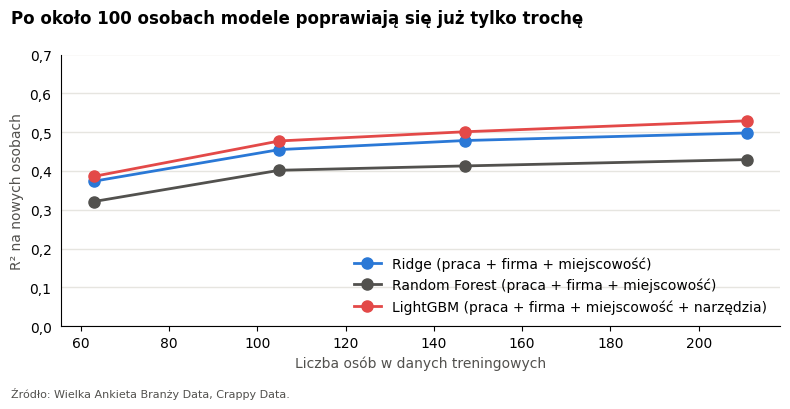

In [82]:
curve_colors = {
    "Ridge (praca + firma + miejscowość)": BLUE,
    "Random Forest (praca + firma + miejscowość)": DARK_GRAY,
    "LightGBM (praca + firma + miejscowość + narzędzia)": RED,
}

fig, ax = plt.subplots(figsize=(8, 4))

for name, color in curve_colors.items():
    rows = curve_results[curve_results["model"] == name]
    ax.plot(rows["people"], rows["r2_new_people"], marker="o", markersize=8, linewidth=2, color=color, label=name)

ax.set_ylim(0, 0.7)
ax.yaxis.set_major_formatter(lambda value, position: polish_number(f"{value:.1f}"))
ax.set_xlabel("Liczba osób w danych treningowych", color=DARK_GRAY)
ax.set_ylabel("R² na nowych osobach", color=DARK_GRAY)
ax.spines["bottom"].set_visible(True)
ax.grid(axis="y", color="#e6e5e0", linewidth=1)
ax.legend(frameon=False, loc="lower right")

fig.suptitle("Po około 100 osobach modele poprawiają się już tylko trochę", x=0.02, ha="left", fontweight="bold")
fig.text(0.02, 0.01, SOURCE, fontsize=8, color=DARK_GRAY)
fig.tight_layout(rect=(0, 0.04, 1, 1))
plt.show()

**Co widzimy:**

- **Największa poprawa jest na początku.** Wszystkie modele poprawiają się między 63 a 105 osobami.
- **Potem wzrost jest powolny.** Od 105 do 211 osób Ridge rośnie z 0,455 do 0,498, a Random Forest z 0,402 do 0,429. LightGBM rośnie z 0,477 do 0,529. Jego wyniki mogą tu wyglądać trochę za dobrze, bo ustawienia wybraliśmy na wszystkich danych.
- **Najlepsze ustawienia LightGBM są bardzo proste.** Każde drzewo ma tylko 2 liście, więc złożone kombinacje cech chyba nie są potrzebne.

**Co to znaczy:** więcej osób pomogłoby prawdopodobnie tylko trochę. Żeby przewidywać zarobki dużo lepiej, ankieta potrzebowałaby nowych informacji, na przykład dokładnego miasta, poziomu umiejętności albo wyników w pracy.

## 3.5 Które cechy są najważniejsze?

Używamy **permutation importance**. Mieszamy wartości jednej kolumny i sprawdzamy, o ile gorszy staje się model. Jeśli model jest dużo gorszy, kolumna była ważna. Robimy to tylko na niewidzianych danych.

Ta funkcja oblicza ważność cech dla jednego modelu.

In [83]:
def average_importance(features, model):
    importance_rows = []
    splitter = KFold(n_splits=5, shuffle=True, random_state=0)

    for train_rows, test_rows in splitter.split(df):
        train = df.iloc[train_rows]
        test = df.iloc[test_rows]

        fitted = make_model(features, model).fit(train[features], train["log_pay"])
        importance = permutation_importance(
            fitted, test[features], test["log_pay"], scoring="r2", n_repeats=10, random_state=0,
        )
        importance_rows.append(importance.importances_mean)

    return pd.Series(np.mean(importance_rows, axis=0), index=features)

Zaczynamy od Ridge.

In [84]:
best_features = feature_sets["Praca + firma + miejscowość"]
best_model = RidgeCV(alphas=np.logspace(-2, 3, 12))

feature_labels = {
    "seniority": "Poziom stanowiska",
    "contract": "Forma zatrudnienia",
    "position": "Stanowisko",
    "company_capital": "Kapitał firmy",
    "experience": "Doświadczenie",
    "company_size": "Wielkość firmy",
    "work_time": "Wymiar pracy",
    "city_size": "Wielkość miejscowości",
    "python": "Python",
    "cloud_warehouse": "Snowflake / BigQuery / Redshift",
    "excel": "Excel / Google Sheets",
}

ridge_importance = average_importance(best_features, best_model)
ridge_importance = ridge_importance.rename(index=feature_labels).sort_values(ascending=False)

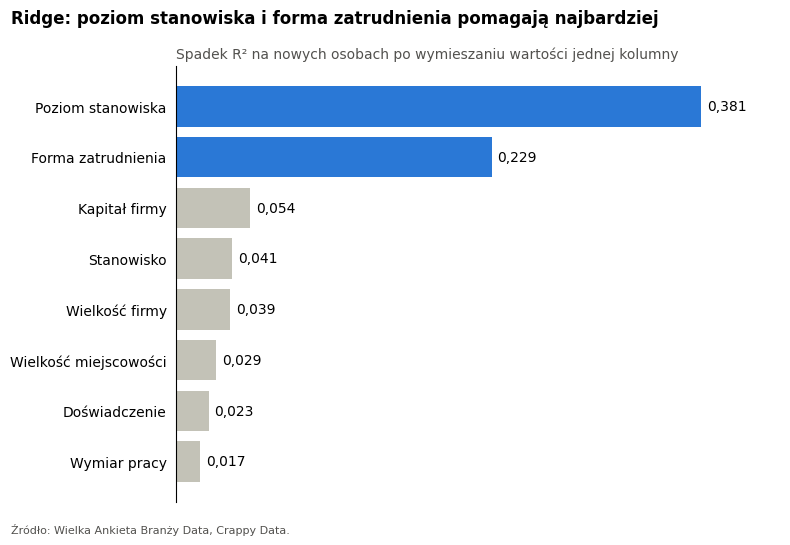

In [85]:
bar_chart(
    ridge_importance,
    "Ridge: poziom stanowiska i forma zatrudnienia pomagają najbardziej",
    "Spadek R² na nowych osobach po wymieszaniu wartości jednej kolumny",
    highlight=["Poziom stanowiska", "Forma zatrudnienia"],
    number_format="{:.3f}",
)

Teraz robimy to samo dla LightGBM. Ten model używa też narzędzi, więc możemy zobaczyć, które narzędzia pomagają.

In [86]:
lightgbm_importance = average_importance(tools_features, final_lightgbm)
lightgbm_importance = lightgbm_importance.rename(index=feature_labels)

# Usuwamy początek nazw narzędzi, na przykład "narzędzia | airflow"
lightgbm_importance = lightgbm_importance.rename(index=lambda name: name.split(" | ")[-1])

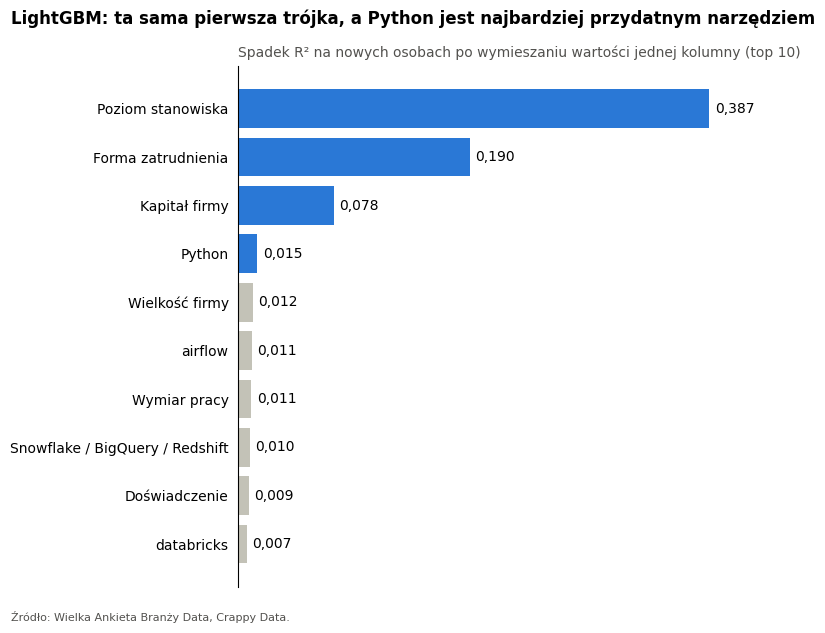

In [87]:
bar_chart(
    lightgbm_importance.sort_values(ascending=False).head(10),
    "LightGBM: ta sama pierwsza trójka, a Python jest najbardziej przydatnym narzędziem",
    "Spadek R² na nowych osobach po wymieszaniu wartości jednej kolumny (top 10)",
    highlight=["Poziom stanowiska", "Forma zatrudnienia", "Kapitał firmy", "Python"],
    number_format="{:.3f}",
)

**Co widzimy:**

- **Oba modele zgadzają się co do pierwszej trójki:** poziom stanowiska (0,381 w Ridge i 0,387 w LightGBM), forma zatrudnienia (0,229 i 0,190) i kapitał firmy (0,054 i 0,078).
- **Wielkość miejscowości dodaje trochę** (0,029 w Ridge).
- **Narzędzia niewiele dodają do przewidywań.** Najbardziej przydatnym narzędziem jest Python (0,015).

To nie znaczy, że pozostałe kolumny nie mają znaczenia. Na przykład doświadczenie ma niski wynik, bo pokrywa się z poziomem stanowiska: gdy mieszamy doświadczenie, model nadal może dostać podobną informację z poziomu stanowiska.

**Czego dowiedzieliśmy się w części 3:** uczenie maszynowe zgadza się z testami i regresją. Najważniejsze są poziom stanowiska i forma zatrudnienia, a kapitał firmy dodaje przydatną informację. Złożone modele mogą dodać trochę dokładności, ale nie zmieniają historii.

Błąd około 23% jest zbyt duży na dokładny kalkulator zarobków. Model jest jednak przydatny do porównywania grup osób o podobnej pracy, a tego potrzebujemy w części 4.

## 3.6 Którego modelu używamy dalej?

LightGBM jest trochę dokładniejszy. Ale w części 4 chcemy oszacować zarobki na podstawie pracy, firmy i wielkości miejscowości danej osoby, a to oszacowanie musi być łatwe do wyjaśnienia. Dlatego głównym modelem jest **Ridge z kolumnami pracy, firmy i miejscowości**, a wyniki sprawdzamy jeszcze LightGBM.

---
# Część 4: Czy ludzie znają swoją wartość na rynku?

Teraz możemy odpowiedzieć na ostatnie pytanie. Dla każdej osoby model szacuje zarobki podobnych osób. Następnie porównujemy trzy rzeczy: prawdziwe zarobki, oszacowane zarobki i odczucie danej osoby.

## 4.1 Szacujemy zarobki podobnych osób

Używamy `cross_val_predict`. Każda osoba dostaje oszacowanie od modelu, który nie widział jej zarobków. To ważne, bo inaczej model mógłby po prostu zapamiętać odpowiedź.

In [88]:
estimate_splits = KFold(n_splits=5, shuffle=True, random_state=0)

log_estimate = cross_val_predict(
    make_model(best_features, best_model),
    df[best_features],
    df["log_pay"],
    cv=estimate_splits,
)

df["estimated_pay"] = np.exp(log_estimate)

**Różnica w zarobkach** (pay gap) to różnica między prawdziwymi a oszacowanymi zarobkami. Dodatnia różnica oznacza, że dana osoba zarabia więcej niż podobne osoby.

In [89]:
df["pay_gap_%"] = (df["pay"] / df["estimated_pay"] - 1) * 100

df["pay_gap_%"].quantile([0.25, 0.5, 0.75]).round(1)

0.25   -14.8
0.50     0.0
0.75    20.5
Name: pay_gap_%, dtype: float64

Jak dokładne jest to oszacowanie? Obliczamy przedział, w którym mieści się różnica dla 8 na 10 osób.

In [90]:
range_low = df["pay_gap_%"].quantile(0.1)
range_high = df["pay_gap_%"].quantile(0.9)

print("8 na 10 osób ma różnicę między (%):", round(range_low, 1), "a", round(range_high, 1))

8 na 10 osób ma różnicę między (%): -28.6 a 41.3


**Co to znaczy:** różnica dla 8 na 10 osób mieści się mniej więcej między -29% a +41%. Oszacowanie jest więc zbyt przybliżone, żeby oceniać jedną osobę. Osoba z różnicą +10% może być po prostu przypadkiem, którego model nie widzi dobrze.

**Decyzja:** różnicy używamy tylko do porównywania **grup** osób. Wyniki powtarzamy też z dużo szerszymi granicami w rozdziale 4.3.

Dzielimy osoby na 3 grupy. Różnicę do 10% traktujemy jako bliską rynkowi, bo model nie jest dokładny.

In [91]:
gap_limits = [-np.inf, -10, 10, np.inf]
gap_names = ["10%+ poniżej podobnych osób", "W granicach 10%", "10%+ powyżej podobnych osób"]

df["real_position"] = pd.cut(df["pay_gap_%"], bins=gap_limits, labels=gap_names)

Zostawiamy osoby, które jasno odpowiedziały, jak oceniają swoje zarobki.

In [92]:
feeling_names = ["Poniżej rynku", "Na poziomie rynku", "Powyżej rynku"]

known_feeling = df[df["feeling"].isin(feeling_names)].copy()

print("Liczba osób:", known_feeling.shape[0])

Liczba osób: 251


Zanim zaczniemy porównywać, sprawdzamy, jak ludzie ogólnie oceniają swoje zarobki i jaka jest ich prawdziwa pozycja.

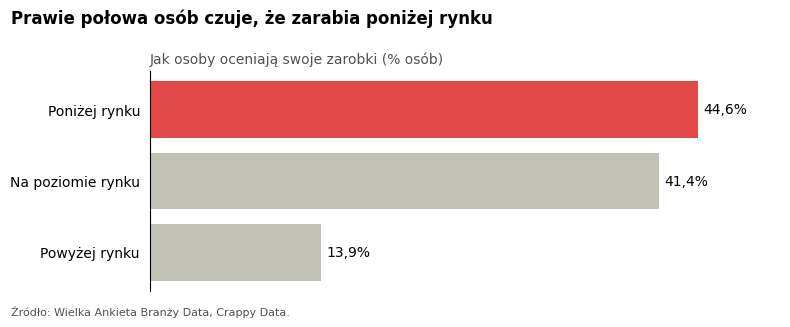

In [93]:
overall_feeling = known_feeling["feeling"].value_counts(normalize=True).loc[feeling_names] * 100

bar_chart(
    overall_feeling,
    "Prawie połowa osób czuje, że zarabia poniżej rynku",
    "Jak osoby oceniają swoje zarobki (% osób)",
    highlight=["Poniżej rynku"],
    number_format="{:.1f}%",
    color=RED,
)

In [94]:
above_estimate = (known_feeling["pay_gap_%"] > 0).mean() * 100

print("Osoby powyżej oszacowania (%):", round(above_estimate, 1))

Osoby powyżej oszacowania (%): 49.4


## 4.2 Porównujemy rzeczywistość i odczucie

Najpierw liczymy osoby w każdej kombinacji.

In [95]:
feeling_counts = pd.crosstab(known_feeling["real_position"], known_feeling["feeling"])
feeling_counts = feeling_counts[feeling_names]
feeling_counts

feeling,Poniżej rynku,Na poziomie rynku,Powyżej rynku
real_position,,,
10%+ poniżej podobnych osób,61,21,6
W granicach 10%,29,34,9
10%+ powyżej podobnych osób,22,49,20


Teraz zamieniamy liczby na procenty w każdym wierszu.

In [96]:
feeling_shares = pd.crosstab(known_feeling["real_position"], known_feeling["feeling"], normalize="index") * 100
feeling_shares = feeling_shares[feeling_names].round(1)

Ten wykres pokazuje procenty.

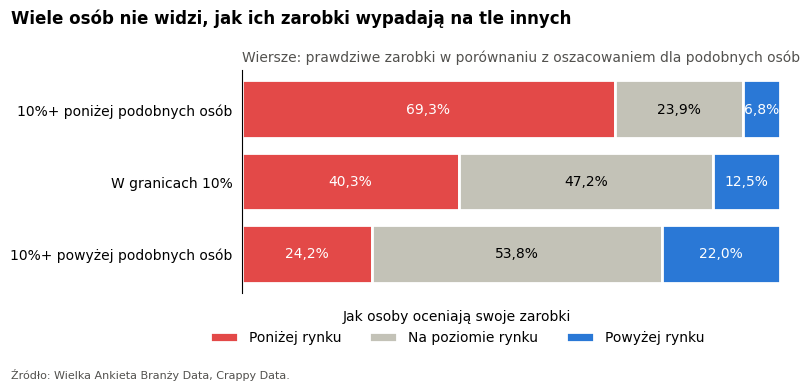

In [97]:
colors = {"Poniżej rynku": RED, "Na poziomie rynku": GRAY, "Powyżej rynku": BLUE}
text_colors = {"Poniżej rynku": "white", "Na poziomie rynku": "black", "Powyżej rynku": "white"}

fig, ax = plt.subplots(figsize=(8, 3.8))

# Rysujemy po kolei każdą kolorową część
left_edge = np.zeros(len(feeling_shares))
for feeling in feeling_names:
    values = feeling_shares[feeling].values
    bars = ax.barh(feeling_shares.index.astype(str), values, left=left_edge, color=colors[feeling], label=feeling, edgecolor="white", linewidth=2)
    ax.bar_label(bars, [polish_number(f"{value:.1f}%") for value in values], label_type="center", color=text_colors[feeling])
    left_edge = left_edge + values

# Porządkujemy wykres i dodajemy tekst
ax.invert_yaxis()
ax.set_xticks([])
ax.set_xlim(0, 100)
ax.legend(title="Jak osoby oceniają swoje zarobki", ncol=3, loc="upper center", bbox_to_anchor=(0.4, -0.02), frameon=False)
fig.suptitle("Wiele osób nie widzi, jak ich zarobki wypadają na tle innych", x=0.02, ha="left", fontweight="bold")
ax.set_title("Wiersze: prawdziwe zarobki w porównaniu z oszacowaniem dla podobnych osób", loc="left", fontsize=10, color=DARK_GRAY)
fig.text(0.02, 0.01, SOURCE, fontsize=8, color=DARK_GRAY)
fig.tight_layout(rect=(0, 0.04, 1, 1))
plt.show()

**Test chi-kwadrat** sprawdza, czy odczucie i prawdziwa pozycja są ze sobą powiązane. Jego założenie jest takie, że oczekiwana liczebność w każdej komórce wynosi co najmniej 5, więc to też sprawdzamy.

In [98]:
chi_square = stats.chi2_contingency(feeling_counts)

print("P-value:", chi_square.pvalue)
print("Najmniejsza oczekiwana liczebność:", round(chi_square.expected_freq.min(), 1))

P-value: 7.28837151882259e-08
Najmniejsza oczekiwana liczebność: 10.0


**V Craméra** pokazuje siłę związku. Przyjmuje wartości od 0 do 1. W przybliżeniu dla tej tabeli 0,07 to mały efekt, 0,21 średni, a 0,35 duży.

In [99]:
people = feeling_counts.values.sum()
cramers_v = np.sqrt(chi_square.statistic / (people * 2))

print("V Craméra:", round(cramers_v, 2))

V Craméra: 0.28


Na koniec liczymy, ile osób ma odczucie zgodne ze swoją prawdziwą pozycją.

In [100]:
matches = {
    "10%+ poniżej podobnych osób": "Poniżej rynku",
    "W granicach 10%": "Na poziomie rynku",
    "10%+ powyżej podobnych osób": "Powyżej rynku",
}

expected_feeling = known_feeling["real_position"].astype(str).map(matches)
same_answer = known_feeling["feeling"] == expected_feeling

print("Odczucie zgodne z oszacowaniem (%):", round(same_answer.mean() * 100, 1))

Odczucie zgodne z oszacowaniem (%): 45.8


Gdyby nie było żadnego związku, ten odsetek wynikałby tylko z tego, jak częste są poszczególne odpowiedzi. Obliczamy go dla porównania.

In [101]:
chance_share = 0
for real_position, feeling in matches.items():
    real_share = (known_feeling["real_position"] == real_position).mean()
    feeling_share = (known_feeling["feeling"] == feeling).mean()
    chance_share = chance_share + real_share * feeling_share

print("Zgodność oczekiwana przypadkowo (%):", round(chance_share * 100, 1))

Zgodność oczekiwana przypadkowo (%): 32.6


**Co widzimy:**

- **Ludzie mają pewne wyczucie swojej pozycji.** Odczucie i prawdziwa pozycja są wyraźnie powiązane (p < 0,001), a związek jest średni do dużego (V Craméra = 0,28). Założenie testu jest spełnione, bo najmniejsza oczekiwana liczebność wynosi 10,0.
- **Ale to wyczucie nie jest dokładne.** Odczucie zgadza się z oszacowaniem u 45,8% osób, a przypadkowo zgadzałoby się u 32,6%.
- **Osoby, które zarabiają mniej, zwykle o tym wiedzą.** Spośród osób zarabiających co najmniej 10% mniej niż podobne osoby 69,3% czuje, że zarabia poniżej rynku.
- **Osoby, które zarabiają więcej, często tego nie widzą.** Spośród osób zarabiających co najmniej 10% więcej niż podobne osoby tylko 22,0% czuje, że zarabia powyżej rynku, a 24,2% nadal czuje, że zarabia poniżej.

**To odpowiada na nasze pierwsze pytanie.** Ogólnie 44,6% osób czuje, że zarabia poniżej rynku, a 13,9% powyżej. Ale mniej więcej połowa osób (49,4%) jest powyżej oszacowania dla podobnych osób, więc wiele osób może być bardziej pesymistycznych, niż wskazują liczby.

**Uwaga:** model to nie prawdziwy rynek pracy. Nie widzi dokładnie umiejętności, dokładnego miasta ani wyników w pracy. Dlatego niektóre osoby, które czują, że zarabiają za mało, mogą mieć rację.

## 4.3 Czy te wyniki zależą od naszych wyborów?

Podjęliśmy kilka ważnych decyzji: granica 10%, uwzględnienie wszystkich form zatrudnienia i użycie Ridge. Teraz zmieniamy każdą z nich i sprawdzamy, czy główny wynik zostaje.

Ta funkcja oblicza główne liczby dla jednego sprawdzenia. Pokazuje tylko potrzebne liczby, więc wszystkie grupy pozostają wystarczająco duże.

In [102]:
def check_result(data, groups, low_group, high_group):
    low_people = data[groups == low_group]
    high_people = data[groups == high_group]

    return {
        "people_in_low_group": len(low_people),
        "people_in_high_group": len(high_people),
        "low_group_feels_below_%": (low_people["feeling"] == "Poniżej rynku").mean() * 100,
        "high_group_feels_below_%": (high_people["feeling"] == "Poniżej rynku").mean() * 100,
        "high_group_feels_above_%": (high_people["feeling"] == "Powyżej rynku").mean() * 100,
    }

Zaczynamy od głównego wyniku, żeby porównać z nim sprawdzenia.

In [103]:
checks = {}

low_name = "10%+ poniżej podobnych osób"
high_name = "10%+ powyżej podobnych osób"

checks["Główny wynik (granica 10%)"] = check_result(known_feeling, known_feeling["real_position"], low_name, high_name)

**Sprawdzenie 1:** granica 15%.

In [104]:
groups_15 = pd.cut(known_feeling["pay_gap_%"], bins=[-np.inf, -15, 15, np.inf], labels=["low", "middle", "high"])

checks["Granica 15%"] = check_result(known_feeling, groups_15, "low", "high")

**Sprawdzenie 2:** granica 30%. Błędy modelu są duże, więc osoby poza tą granicą są wyraźniej powyżej lub poniżej podobnych osób.

In [105]:
groups_30 = pd.cut(known_feeling["pay_gap_%"], bins=[-np.inf, -30, 30, np.inf], labels=["low", "middle", "high"])

checks["Granica 30%"] = check_result(known_feeling, groups_30, "low", "high")

**Sprawdzenie 3:** tylko osoby na pełnym etacie z umową o pracę.

In [106]:
is_employment = known_feeling["contract"] == "Umowa o pracę"
is_full_time = known_feeling["work_time"] == "Pełny etat"
employment_feeling = known_feeling[is_employment & is_full_time]

checks["Tylko umowy o pracę"] = check_result(employment_feeling, employment_feeling["real_position"], low_name, high_name)

**Sprawdzenie 4:** powtarzamy oszacowanie z LightGBM i narzędziami. Ten model widzi też część umiejętności danej osoby.

In [107]:
lightgbm_estimate = cross_val_predict(
    make_model(tools_features, final_lightgbm),
    df[tools_features],
    df["log_pay"],
    cv=estimate_splits,
)

df["lightgbm_gap_%"] = (df["pay"] / np.exp(lightgbm_estimate) - 1) * 100
known_feeling["lightgbm_gap_%"] = df.loc[known_feeling.index, "lightgbm_gap_%"]

gap_correlation = df["pay_gap_%"].corr(df["lightgbm_gap_%"], method="spearman")
print("Korelacja Spearmana między dwiema różnicami:", round(gap_correlation, 2))

Korelacja Spearmana między dwiema różnicami: 0.91


In [108]:
lightgbm_groups = pd.cut(known_feeling["lightgbm_gap_%"], bins=gap_limits, labels=gap_names)

checks["LightGBM z narzędziami"] = check_result(known_feeling, lightgbm_groups, low_name, high_name)

Teraz zbieramy wszystkie wyniki w jednej tabeli.

In [109]:
checks_table = pd.DataFrame(checks).T
checks_table.round(1)

,people_in_low_group,people_in_high_group,low_group_feels_below_%,high_group_feels_below_%,high_group_feels_above_%
Główny wynik (granica 10%),88.0,91.0,69.3,24.2,22.0
Granica 15%,64.0,79.0,76.6,22.8,21.5
Granica 30%,23.0,43.0,91.3,23.3,27.9
Tylko umowy o pracę,68.0,72.0,70.6,27.8,15.3
LightGBM z narzędziami,83.0,89.0,71.1,20.2,24.7


Wykres pokazuje trzy odsetki dla każdego sprawdzenia. Jeśli punkty są w podobnych miejscach, wynik nie zależy od naszych wyborów.

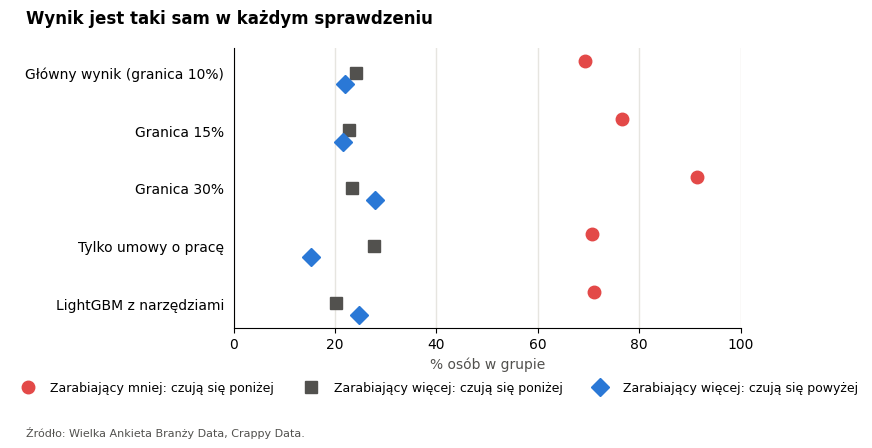

In [110]:
# Każda seria ma swój kolor, znacznik i małe przesunięcie w pionie, żeby punkty się nie zasłaniały
check_series = {
    "Zarabiający mniej: czują się poniżej": ("low_group_feels_below_%", RED, "o", -0.2),
    "Zarabiający więcej: czują się poniżej": ("high_group_feels_below_%", DARK_GRAY, "s", 0),
    "Zarabiający więcej: czują się powyżej": ("high_group_feels_above_%", BLUE, "D", 0.2),
}

fig, ax = plt.subplots(figsize=(8, 4.4))
rows = np.arange(len(checks_table))

for label, (column, color, marker, shift) in check_series.items():
    ax.plot(checks_table[column], rows + shift, marker, color=color, markersize=9, label=label)

ax.set_yticks(rows)
ax.set_yticklabels(checks_table.index)
ax.invert_yaxis()
ax.set_xlim(0, 100)
ax.set_xlabel("% osób w grupie", color=DARK_GRAY)
ax.spines["bottom"].set_visible(True)
ax.grid(axis="x", color="#e6e5e0", linewidth=1)
ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.4, -0.15), ncol=3, fontsize=9)

fig.suptitle("Wynik jest taki sam w każdym sprawdzeniu", x=0.02, ha="left", fontweight="bold")
fig.text(0.02, 0.01, SOURCE, fontsize=8, color=DARK_GRAY)
fig.tight_layout(rect=(0, 0.04, 1, 1))
plt.show()

**Co widzimy:** główny wzór zostaje we wszystkich sprawdzeniach.

- **Większość osób z grupy zarabiającej mniej czuje się poniżej rynku:** od 69,3% do 91,3%.
- **Tylko niewielka część grupy zarabiającej więcej czuje się powyżej rynku:** od 15,3% do 27,9%.
- **Część osób z grupy zarabiającej więcej nadal czuje się poniżej rynku:** od 20,2% do 27,8%.

Oba modele dają bardzo podobne różnice (korelacja Spearmana = 0,91). Przy granicy 30% grupy są mniejsze (23 i 43 osoby), więc te liczby są mniej dokładne.

**Decyzja:** nasz wniosek nie zależy od granicy, od B2B ani od modelu.

## 4.4 Co ma większe znaczenie dla zadowolenia: prawdziwa pozycja czy odczucie?

Jeśli ludzie nie zawsze znają swoją prawdziwą pozycję, to co idzie w parze z zadowoleniem z pracy? Porównujemy jedno i drugie.

In [111]:
by_real_position = known_feeling.groupby("real_position", observed=True)["satisfaction"].mean()
by_feeling = known_feeling.groupby("feeling")["satisfaction"].mean().loc[feeling_names]

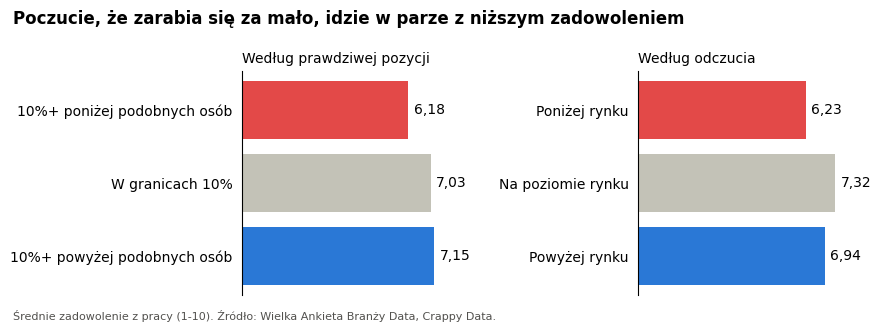

In [112]:
fig, (ax_real, ax_feeling) = plt.subplots(1, 2, figsize=(9, 3.2), sharex=True)

# Po lewej: prawdziwa pozycja. Po prawej: odczucie.
real_bars = ax_real.barh(by_real_position.index.astype(str), by_real_position.values, color=[RED, GRAY, BLUE])
feeling_bars = ax_feeling.barh(by_feeling.index, by_feeling.values, color=[RED, GRAY, BLUE])
ax_real.bar_label(real_bars, [polish_number(f"{value:.2f}") for value in by_real_position.values], padding=4)
ax_feeling.bar_label(feeling_bars, [polish_number(f"{value:.2f}") for value in by_feeling.values], padding=4)

for ax in [ax_real, ax_feeling]:
    ax.invert_yaxis()
    ax.set_xticks([])
    ax.set_xlim(0, 9)
ax_real.set_title("Według prawdziwej pozycji", loc="left", fontsize=10)
ax_feeling.set_title("Według odczucia", loc="left", fontsize=10)

fig.suptitle("Poczucie, że zarabia się za mało, idzie w parze z niższym zadowoleniem", x=0.02, ha="left", fontweight="bold")
fig.text(0.02, 0.01, "Średnie zadowolenie z pracy (1-10). " + SOURCE, fontsize=8, color=DARK_GRAY)
fig.tight_layout(rect=(0, 0.04, 1, 1))
plt.show()

Umieszczamy oba czynniki w jednej regresji. `pay_gap_%` to prawdziwa pozycja, a kolumny tak/nie to odczucia. Grupą porównawczą są osoby, które czują, że zarabiają „na poziomie rynku”.

In [113]:
known_feeling["pay_gap_10"] = known_feeling["pay_gap_%"] / 10
known_feeling["feels_below"] = (known_feeling["feeling"] == "Poniżej rynku").astype(int)
known_feeling["feels_above"] = (known_feeling["feeling"] == "Powyżej rynku").astype(int)

satisfaction_model = smf.ols(
    "satisfaction ~ pay_gap_10 + feels_below + feels_above",
    data=known_feeling,
).fit(cov_type="HC3")

In [114]:
satisfaction_terms = ["pay_gap_10", "feels_below", "feels_above"]

pd.DataFrame({
    "points": satisfaction_model.params[satisfaction_terms],
    "ci_low": satisfaction_model.conf_int().loc[satisfaction_terms, 0],
    "ci_high": satisfaction_model.conf_int().loc[satisfaction_terms, 1],
    "p_value": satisfaction_model.pvalues[satisfaction_terms],
}).round(3)

,points,ci_low,ci_high,p_value
pay_gap_10,0.103,0.005,0.202,0.040
feels_below,-0.875,-1.441,-0.309,0.002
feels_above,-0.422,-1.227,0.384,0.305


**Co widzimy:** gdy patrzymy na oba czynniki razem, z zadowoleniem wiążą się zarówno prawdziwa pozycja, jak i odczucie.

- **Poczucie, że zarabia się poniżej rynku:** zadowolenie niższe o 0,88 punktu (p = 0,002) w porównaniu z poczuciem, że zarabia się na poziomie rynku.
- **Prawdziwa pozycja:** gdy zarobki są o 10 punktów procentowych wyższe niż u podobnych osób, zadowolenie jest wyższe tylko o około 0,10 punktu (p = 0,040).
- **Poczucie, że zarabia się powyżej rynku:** brak wyraźnej różnicy (p = 0,305).

**Co to może znaczyć:** duża prawdziwa różnica ma słabszy związek z zadowoleniem niż samo poczucie, że zarabia się za mało. Na przykład różnica 20 punktów procentowych idzie w parze z około 0,2 punktu.

**Uwaga:** nie wiemy, co jest pierwsze. Niezadowolone osoby mogą też łatwiej czuć, że zarabiają za mało.

## 4.5 Na podstawie czego ludzie oceniają swoje zarobki?

Czy ludzie oceniają swoje zarobki po samej kwocie, czy porównując je z podobnymi osobami? Próbujemy przewidzieć odczucie „poniżej rynku” na podstawie trzech różnych kolumn. **AUC** pokazuje, jak dobrze model rozdziela dwie grupy: 0,5 to losowe zgadywanie, a 1,0 to wynik idealny.

Używamy **regresji logistycznej**, prostego modelu dla pytań tak/nie.

In [115]:
feeling_target = known_feeling["feels_below"]
feeling_splits = RepeatedStratifiedKFold(n_splits=5, n_repeats=5, random_state=0)

feeling_inputs = {
    "Kwota zarobków": ["log_pay"],
    "Zarobki w porównaniu z podobnymi osobami": ["pay_gap_%"],
    "Praca, firma i miejscowość": best_features,
}

In [116]:
feeling_scores = {}

for name, features in feeling_inputs.items():
    model = make_model(features, LogisticRegression(C=0.5, max_iter=3000))
    scores = cross_validate(model, known_feeling[features], feeling_target, cv=feeling_splits, scoring="roc_auc")
    feeling_scores[name] = scores["test_score"]

feeling_results = pd.DataFrame({
    "auc": [scores.mean() for scores in feeling_scores.values()],
    "auc_std": [scores.std() for scores in feeling_scores.values()],
}, index=feeling_scores.keys()).round(3)

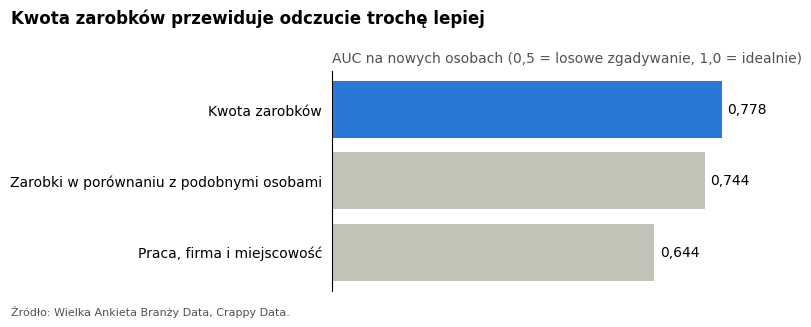

In [117]:
bar_chart(
    feeling_results["auc"],
    "Kwota zarobków przewiduje odczucie trochę lepiej",
    "AUC na nowych osobach (0,5 = losowe zgadywanie, 1,0 = idealnie)",
    highlight=["Kwota zarobków"],
    number_format="{:.3f}",
)

Modele używają tych samych podziałów, więc możemy porównać je podział po podziale.

In [118]:
pay_auc = feeling_scores["Kwota zarobków"]
gap_auc = feeling_scores["Zarobki w porównaniu z podobnymi osobami"]

print("Średnia różnica AUC:", round((pay_auc - gap_auc).mean(), 3))
print("Podziały, w których kwota zarobków jest lepsza (%):", round((pay_auc > gap_auc).mean() * 100))

Średnia różnica AUC: 0.034
Podziały, w których kwota zarobków jest lepsza (%): 64


**Co widzimy:**

- **Kwota zarobków najlepiej przewiduje odczucie** (AUC = 0,778).
- **Zarobki w porównaniu z podobnymi osobami są trochę słabsze** (0,744).
- **Praca, firma i miejscowość są słabsze** (0,644).

**Co to może znaczyć:** ludzie mogą oceniać swoje zarobki bardziej po samej kwocie niż przez porównanie z podobnymi osobami. Ale różnica jest mała (0,034), a kwota zarobków wygrywa tylko w 64% podziałów. To więc tylko słaba wskazówka, a nie mocny dowód.

**Czego dowiedzieliśmy się w części 4:** ludzie mają pewne wyczucie swojej wartości na rynku, ale nie jest ono dokładne. Osoby, które zarabiają mniej, zwykle o tym wiedzą. Osoby, które zarabiają więcej, często tego nie widzą.

---
# Wnioski

## Co odkryliśmy

| Pytanie | Odpowiedź | Jak bardzo jesteśmy pewni? |
|---|---|---|
| Co najbardziej wpływa na zarobki? | Poziom stanowiska i forma zatrudnienia | **Wysoko:** testy, regresja i ML są zgodne |
| Czy firma ma znaczenie? | Firmy międzynarodowe płacą o około 12-14% więcej niż podobnym osobom płacą firmy polskie, a duże firmy o około 10-12% więcej | **Wysoko** dla kapitału, **średnio** dla wielkości: oba wyniki zostają w sprawdzeniach |
| Czy umiejętności mają znaczenie? | Osoby używające Pythona zarabiają o około 10-12% więcej niż podobne osoby | **Średnio:** wynik zostaje w sprawdzeniach, ale nie przechodzi najsurowszej korekty dla umiejętności |
| Czy inne narzędzia mają znaczenie? | Hurtownie danych w chmurze mogą mieć znaczenie (+9-12%) | **Nisko:** w sprawdzeniu wynik nie jest jasny |
| Czy miejsce ma znaczenie? | Osoby z małych miast mają najniższą medianę zarobków | **Nisko do średnio:** efekt jest mały i nie jest jasny po korekcie |
| Czy kierunek wykształcenia ma znaczenie? | Nie widzimy wyraźnej różnicy | **Średnio:** dane zawierają tylko jeden kierunek |
| Czy jest luka płacowa między płciami? | Nie widzimy wyraźnej luki | **Nisko do średnio:** przedział jest szeroki |
| Czy można przewidzieć zarobki? | Częściowo: R² około 0,5 i typowy błąd około 23% | **Wysoko:** sprawdzone na niewidzianych osobach |
| Czy ludzie znają swoją wartość na rynku? | Częściowo: odczucie wiąże się z rzeczywistością, ale osoby zarabiające więcej często tego nie widzą | **Średnio:** oszacowanie jest przybliżone, więc działa tylko dla grup |

## Najważniejsze wnioski (take-home messages)

1. **Porównuj swoje zarobki z prawdziwymi danymi, a nie tylko ze swoim odczuciem.** Wiele osób, które zarabiają więcej niż podobne osoby, tego nie czuje.
2. **Pracodawca może mieć takie samo znaczenie jak umiejętności.** Firma międzynarodowa i Python wiążą się z podobnymi różnicami w zarobkach.
3. **Jeśli pracujesz z danymi i nie używasz Pythona, może to być dobra kolejna umiejętność do nauki.** To związek, a nie gwarancja.
4. **Kierunek studiów może nie ograniczać zarobków w dłuższym okresie.** Wśród podobnych osób nie widzimy wyraźnej różnicy między kierunkami.
5. **Ostrożnie porównuj oferty B2B i umowy o pracę.** Zarobki na rękę są w tych danych dużo wyższe na B2B (mediana 15 000 zł wobec 8 200 zł), ale B2B zwykle nie daje płatnego urlopu ani zwolnienia lekarskiego.
6. **Złożony model nie jest automatycznie lepszy.** Domyślny XGBoost był jednym z najsłabszych modeli. Dostrojony boosting był najdokładniejszy, ale proste modele liniowe były blisko i łatwiej je wyjaśnić.
7. **Lepsze dane mogą pomóc bardziej niż lepszy algorytm.** Krzywe uczenia pokazują, że nowe informacje pomogłyby prawdopodobnie bardziej niż dużo większa liczba osób.

## Ograniczenia projektu

- **Brak przyczyn:** jedna ankieta pokazuje związki, a nie przyczyny.
- **Próba:** osoby same zdecydowały się odpowiedzieć, więc wyniki mogą nie opisywać całej branży.
- **Zarobki:** osoby miały podać średnie miesięczne zarobki po wszystkich podatkach i ZUS, ale nie możemy mieć pewności, że każdy liczył je w ten sposób, szczególnie na B2B.
- **Umiejętności:** wybraliśmy umiejętności po obejrzeniu danych i żadna z nich nie przeszła najsurowszej korekty.
- **Wyniki blisko p = 0,05:** niektóre wyniki zmieniają się po małej zmianie w analizie. Na przykład po dodaniu wielkości miejscowości duże firmy dały jasny wynik, a hurtownie danych w chmurze przestały go dawać w sprawdzeniu dla umów o pracę. Dlatego wyniki blisko 0,05 traktujemy jako niepewne i bardziej ufamy wynikom, które są takie same we wszystkich sprawdzeniach.
- **Oszacowanie:** model nie widzi dokładnie umiejętności, dokładnego miasta ani wyników w pracy, więc „różnica” dla jednej osoby jest tylko przybliżeniem.

## Co dalej

- Pokazać w ankiecie krótki przykład, jak obliczyć średnie miesięczne zarobki na rękę, żeby wszyscy liczyli tak samo.
- Dodać dokładne miasto lub region i dokładny poziom umiejętności.
- Sprawdzić wyniki dla umiejętności na nowych danych z ankiety.

*Źródło: Wielka Ankieta Branży Data, Crappy Data.*